In [1]:
# ============================================================
# RANDOM FOREST MODELLING OF POLLINATOR HABITAT SUITABILITY
# Nyeri County, Kenya
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    accuracy_score,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================================
# CELL 2 — LOAD MODELLING DATA
# ============================================================

# Load the modelling dataset
data = pd.read_csv("modelling_data.csv")

# Display basic information
print("Dataset loaded successfully.")
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

# Display column names
print("\nColumn names:")
print(data.columns.tolist())

Dataset loaded successfully.
Rows: 20000
Columns: 23

Column names:
['OBJECTID', 'Longitude', 'Latitude', 'SOC', 'Aspect', 'Slope', 'PH', 'TRI', 'TWI', 'year', 'NDVI', 'PCI', 'VHI', 'TCI', 'NDBI', 'NDMI', 'SAVI', 'LST', 'SMI', 'pop', 'rain', 'LULC', 'Presence']


In [3]:
# ============================================================
# CELL 3 — DATA QUALITY AND RESPONSE CHECK
# ============================================================

# 1. Display data types
print("DATA TYPES")
print("=" * 60)
print(data.dtypes)

# 2. Check the four study years
print("\nSTUDY YEARS")
print("=" * 60)
print(data["year"].value_counts().sort_index())

# 3. Check pollinator presence/absence
print("\nPOLLINATOR PRESENCE DISTRIBUTION")
print("=" * 60)
print(data["Presence"].value_counts().sort_index())

# 4. Calculate percentages
presence_percent = data["Presence"].value_counts(normalize=True).sort_index() * 100

print("\nPRESENCE PERCENTAGES")
print("=" * 60)
print(presence_percent)

# 5. Check missing values
print("\nMISSING VALUES")
print("=" * 60)

missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) == 0:
    print("No missing values found.")
else:
    print(missing)

# 6. Total rows containing at least one missing value
print("\nTOTAL ROWS WITH MISSING VALUES:", data.isnull().any(axis=1).sum())

DATA TYPES
OBJECTID       int64
Longitude    float64
Latitude     float64
SOC          float64
Aspect       float64
Slope        float64
PH           float64
TRI          float64
TWI          float64
year           int64
NDVI         float64
PCI          float64
VHI          float64
TCI          float64
NDBI         float64
NDMI         float64
SAVI         float64
LST          float64
SMI          float64
pop          float64
rain         float64
LULC         float64
Presence       int64
dtype: object

STUDY YEARS
year
1995    5000
2005    5000
2015    5000
2025    5000
Name: count, dtype: int64

POLLINATOR PRESENCE DISTRIBUTION
Presence
0    19114
1      886
Name: count, dtype: int64

PRESENCE PERCENTAGES
Presence
0    95.57
1     4.43
Name: proportion, dtype: float64

MISSING VALUES
rain      1100
TWI        316
TCI        147
LST        147
SMI        147
VHI        128
pop         26
Aspect      20
Slope       20
NDVI        18
NDMI        18
SAVI        18
LULC        17
PH      

In [4]:
# ============================================================
# CELL 4 — DEFINE RESPONSE AND PREDICTOR VARIABLES
# ============================================================

# Response variable
target = "Presence"

# Predictors to be used by the Random Forest
predictors = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "VHI",
    "TCI",
    "NDBI",
    "NDMI",
    "SAVI",
    "LST",
    "SMI",
    "pop",
    "rain",
    "LULC"
]

print("Response variable:")
print(target)

print("\nNumber of predictors:", len(predictors))

print("\nPredictors:")
for i, predictor in enumerate(predictors, start=1):
    print(f"{i}. {predictor}")

# Verify that all predictors exist in the dataset
missing_predictors = [p for p in predictors if p not in data.columns]

print("\nPredictor verification:")
if len(missing_predictors) == 0:
    print("All predictors found successfully.")
else:
    print("Missing predictors:", missing_predictors)

Response variable:
Presence

Number of predictors: 18

Predictors:
1. SOC
2. Aspect
3. Slope
4. PH
5. TRI
6. TWI
7. NDVI
8. PCI
9. VHI
10. TCI
11. NDBI
12. NDMI
13. SAVI
14. LST
15. SMI
16. pop
17. rain
18. LULC

Predictor verification:
All predictors found successfully.


In [5]:
# ============================================================
# CELL 5 — MISSING VALUES BY PRESENCE CLASS
# ============================================================

# Missing values among presence observations
presence_missing = data.loc[data["Presence"] == 1, predictors].isnull().sum()

# Missing values among background/absence observations
absence_missing = data.loc[data["Presence"] == 0, predictors].isnull().sum()

# Create a comparison table
missing_comparison = pd.DataFrame({
    "Presence_missing": presence_missing,
    "Background_missing": absence_missing,
    "Total_missing": presence_missing + absence_missing
})

# Calculate percentages within each group
n_presence = (data["Presence"] == 1).sum()
n_absence = (data["Presence"] == 0).sum()

missing_comparison["Presence_%"] = (
    missing_comparison["Presence_missing"] / n_presence * 100
)

missing_comparison["Background_%"] = (
    missing_comparison["Background_missing"] / n_absence * 100
)

print("MISSING VALUES BY RESPONSE CLASS")
print("=" * 80)
print(missing_comparison.sort_values("Total_missing", ascending=False))

print("\nTotal presence observations:", n_presence)
print("Total background observations:", n_absence)

MISSING VALUES BY RESPONSE CLASS
        Presence_missing  Background_missing  Total_missing  Presence_%  \
rain                  44                1056           1100    4.966140   
TWI                   14                 302            316    1.580135   
SMI                    5                 142            147    0.564334   
TCI                    5                 142            147    0.564334   
LST                    5                 142            147    0.564334   
VHI                    5                 123            128    0.564334   
pop                    0                  26             26    0.000000   
Aspect                 2                  18             20    0.225734   
Slope                  2                  18             20    0.225734   
NDMI                   0                  18             18    0.000000   
NDVI                   0                  18             18    0.000000   
SAVI                   0                  18             18    0.00

In [6]:
# ============================================================
# CELL 6 — PREPARE MODELLING VARIABLES
# ============================================================

# Predictor matrix
X = data[predictors].copy()

# Response variable
y = data[target].copy()

# Spatial grouping variable
groups = data["OBJECTID"].copy()

# Keep spatial and temporal information separately
spatial_info = data[
    ["OBJECTID", "Longitude", "Latitude", "year"]
].copy()

# Check the resulting structures
print("Predictor matrix shape:", X.shape)
print("Response shape:", y.shape)
print("Number of unique spatial locations:", groups.nunique())

print("\nResponse distribution:")
print(y.value_counts().sort_index())

print("\nNumber of unique years:")
print(data["year"].nunique())

print("\nNumber of unique spatial locations:")
print(data["OBJECTID"].nunique())

Predictor matrix shape: (20000, 18)
Response shape: (20000,)
Number of unique spatial locations: 5000

Response distribution:
Presence
0    19114
1      886
Name: count, dtype: int64

Number of unique years:
4

Number of unique spatial locations:
5000


In [7]:
# ============================================================
# CELL 7 — SPATIALLY INDEPENDENT TRAIN/VALIDATION SPLIT
# ============================================================

# GroupShuffleSplit ensures that the same spatial location
# cannot appear in both training and validation datasets.

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

# Generate the split
train_idx, val_idx = next(
    gss.split(X, y, groups=groups)
)

# Create training and validation datasets
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

groups_train = groups.iloc[train_idx]
groups_val = groups.iloc[val_idx]

# ------------------------------------------------------------
# Check the split
# ------------------------------------------------------------

print("TRAINING DATA")
print("=" * 60)
print("Rows:", len(X_train))
print("Unique locations:", groups_train.nunique())
print("Presence:", y_train.sum())
print("Background:", (y_train == 0).sum())

print("\nVALIDATION DATA")
print("=" * 60)
print("Rows:", len(X_val))
print("Unique locations:", groups_val.nunique())
print("Presence:", y_val.sum())
print("Background:", (y_val == 0).sum())

# ------------------------------------------------------------
# Verify that no spatial location occurs in both datasets
# ------------------------------------------------------------

overlap = set(groups_train.unique()).intersection(
    set(groups_val.unique())
)

print("\nSPATIAL OVERLAP CHECK")
print("=" * 60)
print("Overlapping locations:", len(overlap))

if len(overlap) == 0:
    print("SUCCESS: No spatial locations occur in both datasets.")
else:
    print("WARNING: Spatial overlap detected.")

TRAINING DATA
Rows: 15000
Unique locations: 3750
Presence: 643
Background: 14357

VALIDATION DATA
Rows: 5000
Unique locations: 1250
Presence: 243
Background: 4757

SPATIAL OVERLAP CHECK
Overlapping locations: 0
SUCCESS: No spatial locations occur in both datasets.


In [8]:
# ============================================================
# CELL 8 — PREPROCESSING
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# ------------------------------------------------------------
# Separate numeric and categorical predictors
# ------------------------------------------------------------

numeric_predictors = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "VHI",
    "TCI",
    "NDBI",
    "NDMI",
    "SAVI",
    "LST",
    "SMI",
    "pop",
    "rain"
]

categorical_predictors = ["LULC"]

# ------------------------------------------------------------
# Numeric preprocessing
# ------------------------------------------------------------

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# ------------------------------------------------------------
# Categorical preprocessing
# ------------------------------------------------------------

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

# ------------------------------------------------------------
# Combine preprocessing steps
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_predictors),
        ("categorical", categorical_transformer, categorical_predictors)
    ]
)

# ------------------------------------------------------------
# Fit ONLY on training data
# ------------------------------------------------------------

X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformation to validation data
X_val_processed = preprocessor.transform(X_val)

# ------------------------------------------------------------
# Check results
# ------------------------------------------------------------

print("Original training shape:", X_train.shape)
print("Original validation shape:", X_val.shape)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)

print("\nMissing values after preprocessing:")
print("Training:", np.isnan(X_train_processed).sum())
print("Validation:", np.isnan(X_val_processed).sum())

Original training shape: (15000, 18)
Original validation shape: (5000, 18)

Processed training shape: (15000, 22)
Processed validation shape: (5000, 22)

Missing values after preprocessing:
Training: 0
Validation: 0


In [9]:
# ============================================================
# CELL 9 — TRAIN BASELINE RANDOM FOREST
# ============================================================

# Create the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    max_features="sqrt",
    min_samples_leaf=5
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest trained successfully.")
print("Number of trees:", rf_model.n_estimators)
print("Number of processed predictors:", X_train_processed.shape[1])

Random Forest trained successfully.
Number of trees: 500
Number of processed predictors: 22


In [10]:
# ============================================================
# CELL 10 — RANDOM FOREST VALIDATION
# ============================================================

# Predict probability of pollinator presence
y_val_probability = rf_model.predict_proba(X_val_processed)[:, 1]

# Convert probabilities to binary predictions using 0.50 threshold
y_val_predicted = (y_val_probability >= 0.50).astype(int)

# ------------------------------------------------------------
# Classification metrics
# ------------------------------------------------------------

roc_auc = roc_auc_score(
    y_val,
    y_val_probability
)

pr_auc = average_precision_score(
    y_val,
    y_val_probability
)

accuracy = accuracy_score(
    y_val,
    y_val_predicted
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_val,
    y_val_predicted
)

tn, fp, fn, tp = cm.ravel()

# Sensitivity / recall
sensitivity = tp / (tp + fn)

# Specificity
specificity = tn / (tn + fp)

# ------------------------------------------------------------
# RMSE and R²
# ------------------------------------------------------------

rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_probability
    )
)

r2 = r2_score(
    y_val,
    y_val_probability
)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("RANDOM FOREST VALIDATION RESULTS")
print("=" * 70)

print(f"ROC-AUC:       {roc_auc:.4f}")
print(f"PR-AUC:        {pr_auc:.4f}")
print(f"Accuracy:      {accuracy:.4f}")
print(f"Sensitivity:   {sensitivity:.4f}")
print(f"Specificity:   {specificity:.4f}")
print(f"RMSE:          {rmse:.4f}")
print(f"R²:            {r2:.4f}")

print("\nCONFUSION MATRIX")
print("=" * 70)
print(cm)

print("\nCLASSIFICATION REPORT")
print("=" * 70)
print(
    classification_report(
        y_val,
        y_val_predicted,
        target_names=["Background", "Presence"],
        digits=4
    )
)

RANDOM FOREST VALIDATION RESULTS
ROC-AUC:       0.6653
PR-AUC:        0.0903
Accuracy:      0.9420
Sensitivity:   0.0453
Specificity:   0.9878
RMSE:          0.2730
R²:            -0.6116

CONFUSION MATRIX
[[4699   58]
 [ 232   11]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Background     0.9530    0.9878    0.9701      4757
    Presence     0.1594    0.0453    0.0705       243

    accuracy                         0.9420      5000
   macro avg     0.5562    0.5165    0.5203      5000
weighted avg     0.9144    0.9420    0.9263      5000



In [11]:
# ============================================================
# CELL 11 — PREDICTED PROBABILITY DISTRIBUTION
# ============================================================

# Separate predicted probabilities by observed class
presence_probabilities = y_val_probability[y_val.values == 1]
background_probabilities = y_val_probability[y_val.values == 0]

print("PREDICTED PROBABILITY SUMMARY")
print("=" * 70)

print("\nObserved PRESENCE locations:")
print(pd.Series(presence_probabilities).describe())

print("\nObserved BACKGROUND locations:")
print(pd.Series(background_probabilities).describe())

# Compare mean and median probabilities
print("\nMEAN PROBABILITY")
print("=" * 70)
print(f"Presence:   {presence_probabilities.mean():.4f}")
print(f"Background: {background_probabilities.mean():.4f}")

print("\nMEDIAN PROBABILITY")
print("=" * 70)
print(f"Presence:   {np.median(presence_probabilities):.4f}")
print(f"Background: {np.median(background_probabilities):.4f}")

# Percentage of observations above several probability thresholds
thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]

print("\nPERCENTAGE ABOVE PROBABILITY THRESHOLDS")
print("=" * 70)

for threshold in thresholds:
    presence_above = (presence_probabilities >= threshold).mean() * 100
    background_above = (background_probabilities >= threshold).mean() * 100
    
    print(
        f"Threshold {threshold:.2f} | "
        f"Presence: {presence_above:6.2f}% | "
        f"Background: {background_above:6.2f}%"
    )

PREDICTED PROBABILITY SUMMARY

Observed PRESENCE locations:
count    243.000000
mean       0.261519
std        0.124327
min        0.018852
25%        0.164536
50%        0.245124
75%        0.341169
max        0.627481
dtype: float64

Observed BACKGROUND locations:
count    4757.000000
mean        0.190734
std         0.115336
min         0.000000
25%         0.104864
50%         0.174336
75%         0.259453
max         0.707128
dtype: float64

MEAN PROBABILITY
Presence:   0.2615
Background: 0.1907

MEDIAN PROBABILITY
Presence:   0.2451
Background: 0.1743

PERCENTAGE ABOVE PROBABILITY THRESHOLDS
Threshold 0.10 | Presence:  91.77% | Background:  76.48%
Threshold 0.20 | Presence:  62.96% | Background:  41.62%
Threshold 0.30 | Presence:  35.39% | Background:  16.46%
Threshold 0.40 | Presence:  12.76% | Background:   5.42%
Threshold 0.50 | Presence:   4.53% | Background:   1.22%


RANDOM FOREST VARIABLE IMPORTANCE
              Feature  Importance
         numeric__PCI    0.091048
         numeric__LST    0.065969
         numeric__SMI    0.058445
         numeric__TRI    0.058138
         numeric__VHI    0.057919
         numeric__TCI    0.056509
        numeric__rain    0.056209
        numeric__NDVI    0.055286
        numeric__SAVI    0.055267
         numeric__pop    0.055256
      numeric__Aspect    0.054396
         numeric__SOC    0.054372
         numeric__TWI    0.053382
          numeric__PH    0.052964
       numeric__Slope    0.052659
        numeric__NDMI    0.046027
        numeric__NDBI    0.045477
categorical__LULC_4.0    0.012457
categorical__LULC_3.0    0.005127
categorical__LULC_1.0    0.004957
categorical__LULC_2.0    0.004351
categorical__LULC_0.0    0.003786


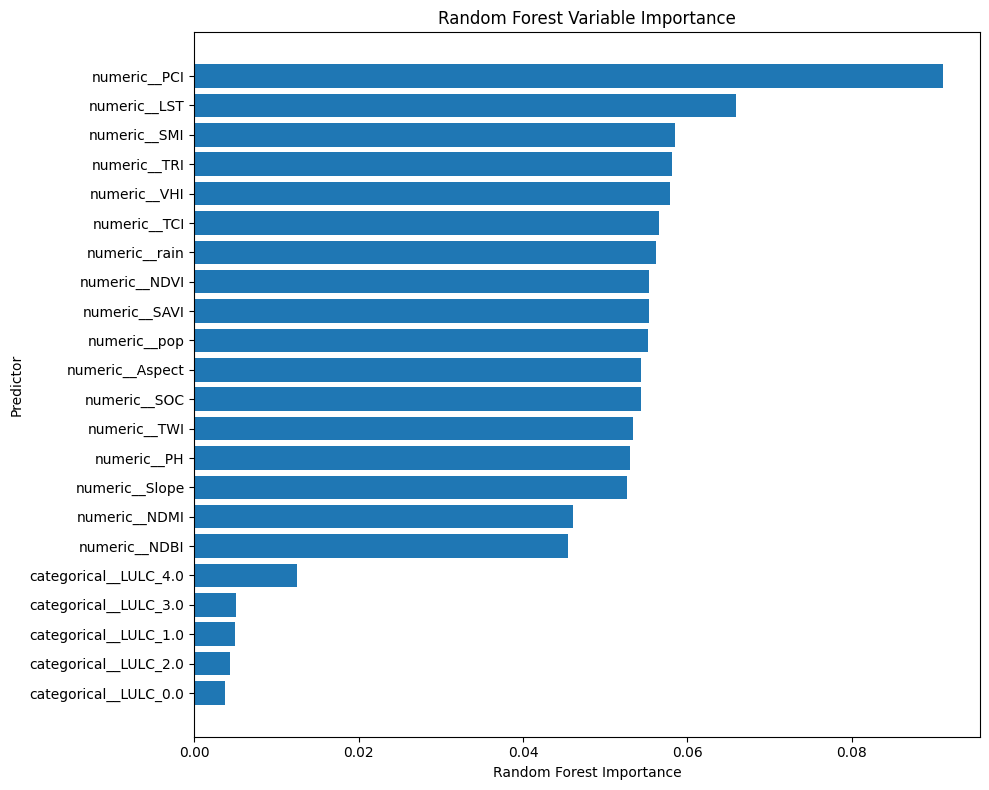

In [12]:
# ============================================================
# CELL 12 — RANDOM FOREST VARIABLE IMPORTANCE
# ============================================================

# Get the names of the processed predictors
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest importance values
importance_values = rf_model.feature_importances_

# Create importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

# Display all features
print("RANDOM FOREST VARIABLE IMPORTANCE")
print("=" * 70)
print(importance_df.to_string(index=False))

# ------------------------------------------------------------
# Plot variable importance
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Random Forest Importance")
plt.ylabel("Predictor")
plt.title("Random Forest Variable Importance")

plt.tight_layout()
plt.show()

PREDICTOR CORRELATION MATRIX
         SOC  Aspect  Slope    PH   TRI   TWI  NDVI   PCI   VHI   TCI  NDBI  NDMI  SAVI   LST   SMI   pop  rain
SOC     1.00    0.01   0.40 -0.62  0.20 -0.32  0.49 -0.02  0.69  0.79  0.37  0.37  0.36 -0.77  0.79  0.04  0.62
Aspect  0.01    1.00   0.04  0.01 -0.02  0.02  0.02  0.02  0.05  0.08  0.03  0.03 -0.09 -0.08  0.08 -0.01 -0.06
Slope   0.40    0.04   1.00 -0.41  0.51 -0.11  0.37 -0.01  0.42  0.41  0.37  0.37  0.28 -0.40  0.41  0.01  0.35
PH     -0.62    0.01  -0.41  1.00 -0.27  0.25 -0.66  0.00 -0.70 -0.65 -0.63 -0.63 -0.58  0.64 -0.65 -0.02 -0.54
TRI     0.20   -0.02   0.51 -0.27  1.00 -0.03  0.24  0.00  0.25  0.22  0.25  0.26  0.20 -0.22  0.22 -0.01  0.25
TWI    -0.32    0.02  -0.11  0.25 -0.03  1.00 -0.11  0.01 -0.20 -0.26 -0.07 -0.07 -0.09  0.25 -0.26 -0.01 -0.19
NDVI    0.49    0.02   0.37 -0.66  0.24 -0.11  1.00  0.18  0.90  0.70  0.93  0.93  0.90 -0.69  0.70  0.02  0.47
PCI    -0.02    0.02  -0.01  0.00  0.00  0.01  0.18  1.00  0.08  0.08  0.18

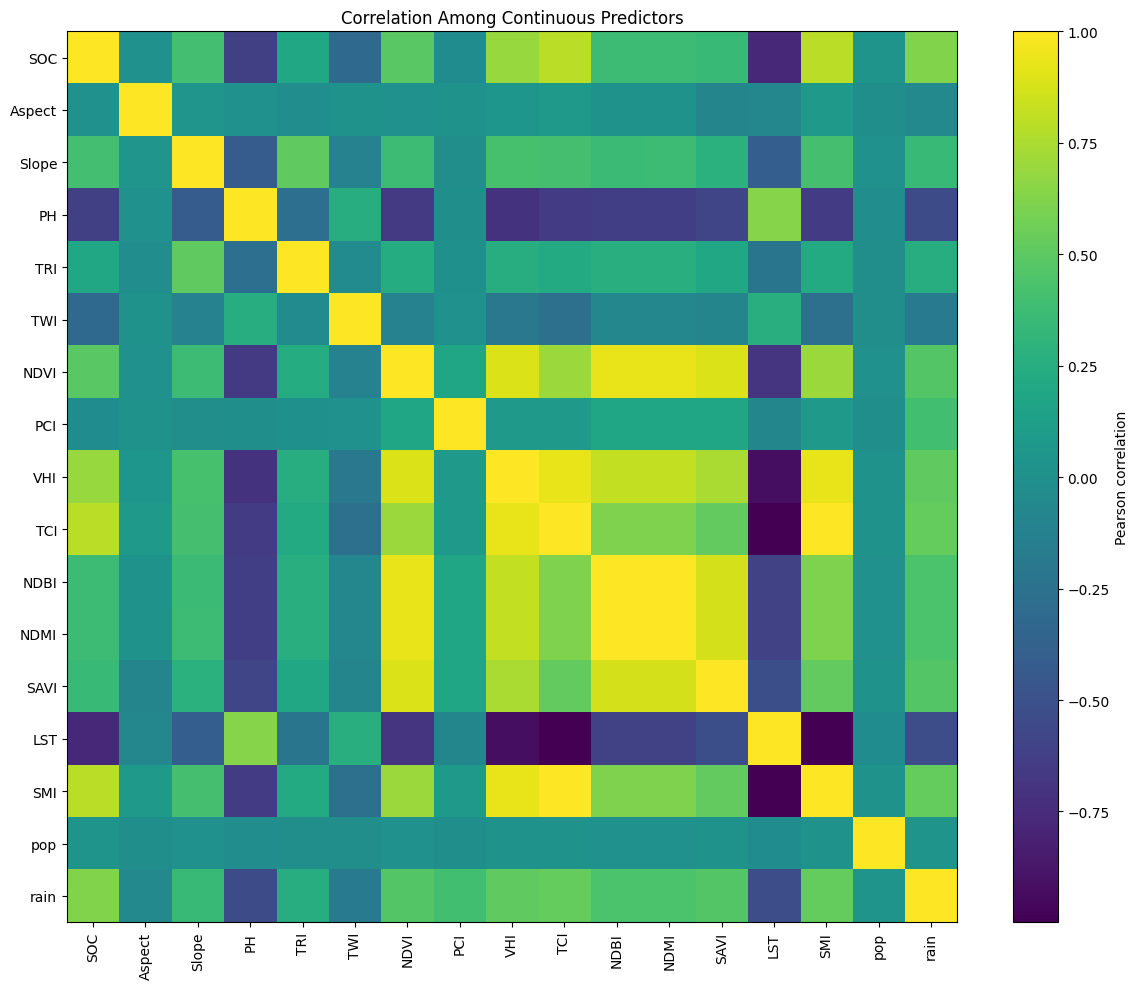

In [13]:
# ============================================================
# CELL 13 — PREDICTOR CORRELATION ANALYSIS
# ============================================================

# Select continuous predictors only
continuous_data = data[numeric_predictors].copy()

# Calculate Pearson correlation matrix
correlation_matrix = continuous_data.corr()

# Display the correlation matrix
print("PREDICTOR CORRELATION MATRIX")
print("=" * 70)

print(
    correlation_matrix.round(2).to_string()
)

# ------------------------------------------------------------
# Plot correlation matrix
# ------------------------------------------------------------

plt.figure(figsize=(12, 10))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Pearson correlation"
)

plt.xticks(
    range(len(numeric_predictors)),
    numeric_predictors,
    rotation=90
)

plt.yticks(
    range(len(numeric_predictors)),
    numeric_predictors
)

plt.title("Correlation Among Continuous Predictors")

plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# CELL 14 — IDENTIFY HIGHLY CORRELATED PREDICTOR PAIRS
# ============================================================

threshold = 0.70

corr_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_pairs.columns = ["Predictor_1", "Predictor_2", "Correlation"]

high_corr_pairs = (
    corr_pairs[
        corr_pairs["Correlation"].abs() >= threshold
    ]
    .sort_values("Correlation", key=lambda x: x.abs(), ascending=False)
)

print("HIGHLY CORRELATED PREDICTOR PAIRS (|r| >= 0.70)")
print("=" * 70)
print(high_corr_pairs.to_string(index=False))

HIGHLY CORRELATED PREDICTOR PAIRS (|r| >= 0.70)
Predictor_1 Predictor_2  Correlation
       NDBI        NDMI     1.000000
        TCI         SMI     0.999997
        LST         SMI    -0.998281
        TCI         LST    -0.998235
       NDVI        NDBI     0.933739
       NDVI        NDMI     0.933739
        VHI         TCI     0.932613
        VHI         SMI     0.932416
        VHI         LST    -0.927023
       NDVI        SAVI     0.897225
       NDVI         VHI     0.895429
       NDBI        SAVI     0.871922
       NDMI        SAVI     0.871922
        VHI        NDMI     0.813412
        VHI        NDBI     0.813342
        SOC         TCI     0.791196
        SOC         SMI     0.791070
        SOC         LST    -0.773670
        VHI        SAVI     0.745782
         PH         VHI    -0.702249


In [15]:
# ============================================================
# CELL 15 — DEFINE REDUCED PREDICTOR SET
# ============================================================

reduced_predictors = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "LST",
    "pop",
    "rain",
    "LULC"
]

removed_predictors = [
    p for p in predictors
    if p not in reduced_predictors
]

print("REDUCED PREDICTOR SET")
print("=" * 70)

print(f"Original predictors: {len(predictors)}")
print(f"Reduced predictors:  {len(reduced_predictors)}")
print()

print("Predictors retained:")
for p in reduced_predictors:
    print("  -", p)

print()
print("Predictors removed because of strong redundancy:")
for p in removed_predictors:
    print("  -", p)

REDUCED PREDICTOR SET
Original predictors: 18
Reduced predictors:  12

Predictors retained:
  - SOC
  - Aspect
  - Slope
  - PH
  - TRI
  - TWI
  - NDVI
  - PCI
  - LST
  - pop
  - rain
  - LULC

Predictors removed because of strong redundancy:
  - VHI
  - TCI
  - NDBI
  - NDMI
  - SAVI
  - SMI


In [16]:
# ============================================================
# CELL 16 — PREPARE REDUCED PREDICTOR DATA
# ============================================================

X_train_reduced = X_train[reduced_predictors].copy()
X_val_reduced = X_val[reduced_predictors].copy()

numeric_reduced = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "LST",
    "pop",
    "rain"
]

categorical_reduced = ["LULC"]

numeric_transformer_reduced = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer_reduced = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor_reduced = ColumnTransformer([
    ("numeric", numeric_transformer_reduced, numeric_reduced),
    ("categorical", categorical_transformer_reduced, categorical_reduced)
])

X_train_reduced_processed = preprocessor_reduced.fit_transform(
    X_train_reduced
)

X_val_reduced_processed = preprocessor_reduced.transform(
    X_val_reduced
)

print("REDUCED DATA PREPARATION")
print("=" * 70)
print("Original training shape:", X_train.shape)
print("Original validation shape:", X_val.shape)
print()
print("Reduced training shape:", X_train_reduced.shape)
print("Reduced validation shape:", X_val_reduced.shape)
print()
print("Processed training shape:", X_train_reduced_processed.shape)
print("Processed validation shape:", X_val_reduced_processed.shape)
print()
print(
    "Missing values after preprocessing — training:",
    np.isnan(X_train_reduced_processed).sum()
)
print(
    "Missing values after preprocessing — validation:",
    np.isnan(X_val_reduced_processed).sum()
)

REDUCED DATA PREPARATION
Original training shape: (15000, 18)
Original validation shape: (5000, 18)

Reduced training shape: (15000, 12)
Reduced validation shape: (5000, 12)

Processed training shape: (15000, 16)
Processed validation shape: (5000, 16)

Missing values after preprocessing — training: 0
Missing values after preprocessing — validation: 0


In [17]:
# ============================================================
# CELL 17 — TRAIN REDUCED RANDOM FOREST
# ============================================================

rf_reduced = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    max_features="sqrt",
    min_samples_leaf=5
)

rf_reduced.fit(
    X_train_reduced_processed,
    y_train
)

print("REDUCED RANDOM FOREST TRAINING COMPLETE")
print("=" * 70)
print("Number of trees:", rf_reduced.n_estimators)
print("Processed features:", X_train_reduced_processed.shape[1])
print("Training observations:", X_train_reduced_processed.shape[0])

REDUCED RANDOM FOREST TRAINING COMPLETE
Number of trees: 500
Processed features: 16
Training observations: 15000


In [18]:
# ============================================================
# CELL 18 — VALIDATE REDUCED RANDOM FOREST
# ============================================================

y_val_probability_reduced = rf_reduced.predict_proba(
    X_val_reduced_processed
)[:, 1]

y_val_predicted_reduced = (
    y_val_probability_reduced >= 0.50
).astype(int)

# Performance metrics
roc_auc_reduced = roc_auc_score(
    y_val,
    y_val_probability_reduced
)

pr_auc_reduced = average_precision_score(
    y_val,
    y_val_probability_reduced
)

accuracy_reduced = accuracy_score(
    y_val,
    y_val_predicted_reduced
)

cm_reduced = confusion_matrix(
    y_val,
    y_val_predicted_reduced
)

tn_r, fp_r, fn_r, tp_r = cm_reduced.ravel()

sensitivity_reduced = tp_r / (tp_r + fn_r)

specificity_reduced = tn_r / (tn_r + fp_r)

rmse_reduced = np.sqrt(
    mean_squared_error(
        y_val,
        y_val_probability_reduced
    )
)

r2_reduced = r2_score(
    y_val,
    y_val_probability_reduced
)

# Print results
print("REDUCED RANDOM FOREST — VALIDATION RESULTS")
print("=" * 70)

print(f"ROC-AUC:      {roc_auc_reduced:.4f}")
print(f"PR-AUC:       {pr_auc_reduced:.4f}")
print(f"Accuracy:     {accuracy_reduced:.4f}")
print(f"Sensitivity:  {sensitivity_reduced:.4f}")
print(f"Specificity:  {specificity_reduced:.4f}")
print(f"RMSE:         {rmse_reduced:.4f}")
print(f"R²:           {r2_reduced:.4f}")

print("\nConfusion Matrix:")
print(cm_reduced)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_val_predicted_reduced,
        target_names=["Background", "Presence"]
    )
)

REDUCED RANDOM FOREST — VALIDATION RESULTS
ROC-AUC:      0.6811
PR-AUC:       0.0958
Accuracy:     0.9380
Sensitivity:  0.0412
Specificity:  0.9838
RMSE:         0.2747
R²:           -0.6321

Confusion Matrix:
[[4680   77]
 [ 233   10]]

Classification Report:
              precision    recall  f1-score   support

  Background       0.95      0.98      0.97      4757
    Presence       0.11      0.04      0.06       243

    accuracy                           0.94      5000
   macro avg       0.53      0.51      0.51      5000
weighted avg       0.91      0.94      0.92      5000



In [19]:
# ============================================================
# CELL 19 — REDUCED MODEL VARIABLE IMPORTANCE
# ============================================================

feature_names_reduced = (
    numeric_reduced +
    list(
        preprocessor_reduced
        .named_transformers_["categorical"]
        .named_steps["onehot"]
        .get_feature_names_out(categorical_reduced)
    )
)

importance_reduced = pd.DataFrame({
    "Feature": feature_names_reduced,
    "Importance": rf_reduced.feature_importances_
})

importance_reduced = (
    importance_reduced
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("REDUCED RANDOM FOREST — VARIABLE IMPORTANCE")
print("=" * 70)
print(importance_reduced.to_string(index=False))

REDUCED RANDOM FOREST — VARIABLE IMPORTANCE
 Feature  Importance
     PCI    0.128282
     LST    0.113883
    NDVI    0.090980
     TRI    0.082824
     pop    0.079832
     TWI    0.079518
  Aspect    0.079021
     SOC    0.078179
   Slope    0.076691
    rain    0.076236
      PH    0.074509
LULC_4.0    0.015910
LULC_1.0    0.006820
LULC_3.0    0.006478
LULC_2.0    0.005637
LULC_0.0    0.005200


In [20]:
# ============================================================
# CELL 20 — RANDOM FOREST HYPERPARAMETER CANDIDATES
# ============================================================

rf_candidates = [
    {
        "name": "Baseline",
        "max_features": "sqrt",
        "min_samples_leaf": 5,
        "max_depth": None,
        "class_weight": "balanced"
    },
    {
        "name": "Larger Leaf",
        "max_features": "sqrt",
        "min_samples_leaf": 10,
        "max_depth": None,
        "class_weight": "balanced"
    },
    {
        "name": "Smaller Leaf",
        "max_features": "sqrt",
        "min_samples_leaf": 2,
        "max_depth": None,
        "class_weight": "balanced"
    },
    {
        "name": "More Features",
        "max_features": 0.7,
        "min_samples_leaf": 5,
        "max_depth": None,
        "class_weight": "balanced"
    },
    {
        "name": "Limited Depth",
        "max_features": "sqrt",
        "min_samples_leaf": 5,
        "max_depth": 15,
        "class_weight": "balanced"
    },
    {
        "name": "Balanced Subsample",
        "max_features": "sqrt",
        "min_samples_leaf": 5,
        "max_depth": None,
        "class_weight": "balanced_subsample"
    }
]

print("RANDOM FOREST HYPERPARAMETER CANDIDATES")
print("=" * 70)

for i, candidate in enumerate(rf_candidates, start=1):
    print(f"{i}. {candidate['name']}")
    print(
        f"   max_features={candidate['max_features']}, "
        f"min_samples_leaf={candidate['min_samples_leaf']}, "
        f"max_depth={candidate['max_depth']}, "
        f"class_weight={candidate['class_weight']}"
    )

RANDOM FOREST HYPERPARAMETER CANDIDATES
1. Baseline
   max_features=sqrt, min_samples_leaf=5, max_depth=None, class_weight=balanced
2. Larger Leaf
   max_features=sqrt, min_samples_leaf=10, max_depth=None, class_weight=balanced
3. Smaller Leaf
   max_features=sqrt, min_samples_leaf=2, max_depth=None, class_weight=balanced
4. More Features
   max_features=0.7, min_samples_leaf=5, max_depth=None, class_weight=balanced
5. Limited Depth
   max_features=sqrt, min_samples_leaf=5, max_depth=15, class_weight=balanced
6. Balanced Subsample
   max_features=sqrt, min_samples_leaf=5, max_depth=None, class_weight=balanced_subsample


In [21]:
# ============================================================
# CELL 21 — RANDOM FOREST HYPERPARAMETER COMPARISON
# ============================================================

tuning_results = []
tuning_models = {}

for candidate in rf_candidates:

    print(f"Training: {candidate['name']}...")

    model = RandomForestClassifier(
        n_estimators=500,
        max_features=candidate["max_features"],
        min_samples_leaf=candidate["min_samples_leaf"],
        max_depth=candidate["max_depth"],
        class_weight=candidate["class_weight"],
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_train_reduced_processed,
        y_train
    )

    # Validation probabilities
    probability = model.predict_proba(
        X_val_reduced_processed
    )[:, 1]

    # Validation predictions
    predicted = (
        probability >= 0.50
    ).astype(int)

    # Metrics
    roc_auc_value = roc_auc_score(
        y_val,
        probability
    )

    pr_auc_value = average_precision_score(
        y_val,
        probability
    )

    accuracy_value = accuracy_score(
        y_val,
        predicted
    )

    rmse_value = np.sqrt(
        mean_squared_error(
            y_val,
            probability
        )
    )

    tuning_results.append({
        "Model": candidate["name"],
        "ROC_AUC": roc_auc_value,
        "PR_AUC": pr_auc_value,
        "Accuracy": accuracy_value,
        "RMSE": rmse_value
    })

    tuning_models[candidate["name"]] = model

tuning_results_df = (
    pd.DataFrame(tuning_results)
    .sort_values(
        "PR_AUC",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nHYPERPARAMETER TUNING RESULTS")
print("=" * 70)

print(
    tuning_results_df.round(4).to_string(index=False)
)

Training: Baseline...
Training: Larger Leaf...
Training: Smaller Leaf...
Training: More Features...
Training: Limited Depth...
Training: Balanced Subsample...

HYPERPARAMETER TUNING RESULTS
             Model  ROC_AUC  PR_AUC  Accuracy   RMSE
     Limited Depth   0.6871  0.0998    0.9008 0.3160
Balanced Subsample   0.6848  0.0969    0.9510 0.2259
       Larger Leaf   0.6850  0.0959    0.9056 0.3208
          Baseline   0.6811  0.0958    0.9380 0.2747
     More Features   0.6740  0.0954    0.9336 0.2707
      Smaller Leaf   0.6726  0.0913    0.9494 0.2350


In [22]:
# ============================================================
# CELL 22 — SELECT BEST RF CONFIGURATION
# ============================================================

best_model_name = tuning_results_df.iloc[0]["Model"]
best_model = tuning_models[best_model_name]

best_result = tuning_results_df.iloc[0]

print("BEST RANDOM FOREST MODEL")
print("=" * 70)

print("Model:", best_model_name)
print(f"ROC-AUC: {best_result['ROC_AUC']:.4f}")
print(f"PR-AUC:  {best_result['PR_AUC']:.4f}")
print(f"RMSE:    {best_result['RMSE']:.4f}")

print("\nModel parameters:")
print(best_model.get_params())

BEST RANDOM FOREST MODEL
Model: Limited Depth
ROC-AUC: 0.6871
PR-AUC:  0.0998
RMSE:    0.3160

Model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 15, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 500, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [23]:
# ============================================================
# CELL 23 — CHECK SPATIAL CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import GroupKFold

spatial_cv = GroupKFold(n_splits=5)

print("SPATIAL CROSS-VALIDATION")
print("=" * 70)
print("Method: GroupKFold")
print("Number of folds:", spatial_cv.n_splits)
print("Grouping variable: OBJECTID")

print(
    "\nTotal unique spatial locations:",
    groups.nunique()
)

print(
    "Expected locations per fold:",
    groups.nunique() / spatial_cv.n_splits
)

SPATIAL CROSS-VALIDATION
Method: GroupKFold
Number of folds: 5
Grouping variable: OBJECTID

Total unique spatial locations: 5000
Expected locations per fold: 1000.0


In [24]:
# ============================================================
# CELL 24 — VERIFY SPATIAL FOLDS
# ============================================================

fold_summary = []

for fold, (train_idx, val_idx) in enumerate(
    spatial_cv.split(X_train_reduced, y_train, groups=groups_train), start=1
):
    
    train_groups = set(groups_train.iloc[train_idx])
    val_groups = set(groups_train.iloc[val_idx])
    
    overlap = train_groups.intersection(val_groups)
    
    fold_summary.append({
        "Fold": fold,
        "Train_rows": len(train_idx),
        "Validation_rows": len(val_idx),
        "Train_locations": len(train_groups),
        "Validation_locations": len(val_groups),
        "Spatial_overlap": len(overlap),
        "Train_presence": int(y_train.iloc[train_idx].sum()),
        "Validation_presence": int(y_train.iloc[val_idx].sum())
    })

fold_summary_df = pd.DataFrame(fold_summary)

print(fold_summary_df.to_string(index=False))

 Fold  Train_rows  Validation_rows  Train_locations  Validation_locations  Spatial_overlap  Train_presence  Validation_presence
    1       12000             3000             3000                   750                0             517                  126
    2       12000             3000             3000                   750                0             523                  120
    3       12000             3000             3000                   750                0             515                  128
    4       12000             3000             3000                   750                0             507                  136
    5       12000             3000             3000                   750                0             510                  133


In [25]:
# ============================================================
# CELL 25 — 5-FOLD SPATIAL CROSS-VALIDATION
# ============================================================

cv_results = []

for fold, (train_idx, val_idx) in enumerate(
    spatial_cv.split(X_train_reduced, y_train, groups=groups_train), start=1
):
    
    print(f"Running Fold {fold}...")
    
    # Split data
    X_fold_train = X_train_reduced.iloc[train_idx].copy()
    X_fold_val = X_train_reduced.iloc[val_idx].copy()
    
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]
    
    # Preprocess using training fold only
    fold_preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median"))
                ]),
                numeric_reduced
            ),
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]),
                categorical_reduced
            )
        ]
    )
    
    X_fold_train_processed = fold_preprocessor.fit_transform(X_fold_train)
    X_fold_val_processed = fold_preprocessor.transform(X_fold_val)
    
    # Train selected Limited Depth RF
    fold_model = RandomForestClassifier(
        n_estimators=500,
        max_features="sqrt",
        min_samples_leaf=5,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
    
    fold_model.fit(X_fold_train_processed, y_fold_train)
    
    # Predict probabilities
    y_prob = fold_model.predict_proba(X_fold_val_processed)[:, 1]
    
    # Metrics
    roc_auc = roc_auc_score(y_fold_val, y_prob)
    pr_auc = average_precision_score(y_fold_val, y_prob)
    
    cv_results.append({
        "Fold": fold,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "Validation_Presence": int(y_fold_val.sum()),
        "Validation_Background": int((y_fold_val == 0).sum())
    })
    
    print(
        f"Fold {fold}: "
        f"ROC-AUC = {roc_auc:.4f}, "
        f"PR-AUC = {pr_auc:.4f}"
    )

cv_results_df = pd.DataFrame(cv_results)

print("\n" + "=" * 70)
print("5-FOLD SPATIAL CROSS-VALIDATION RESULTS")
print("=" * 70)

print(cv_results_df.to_string(index=False))

print("\nMEAN ± STANDARD DEVIATION")
print("-" * 70)

print(
    f"ROC-AUC: "
    f"{cv_results_df['ROC_AUC'].mean():.4f} ± "
    f"{cv_results_df['ROC_AUC'].std():.4f}"
)

print(
    f"PR-AUC: "
    f"{cv_results_df['PR_AUC'].mean():.4f} ± "
    f"{cv_results_df['PR_AUC'].std():.4f}"
)

Running Fold 1...
Fold 1: ROC-AUC = 0.6788, PR-AUC = 0.0779
Running Fold 2...
Fold 2: ROC-AUC = 0.6300, PR-AUC = 0.0825
Running Fold 3...
Fold 3: ROC-AUC = 0.6284, PR-AUC = 0.0669
Running Fold 4...
Fold 4: ROC-AUC = 0.6208, PR-AUC = 0.0671
Running Fold 5...
Fold 5: ROC-AUC = 0.6779, PR-AUC = 0.0861

5-FOLD SPATIAL CROSS-VALIDATION RESULTS
 Fold  ROC_AUC   PR_AUC  Validation_Presence  Validation_Background
    1 0.678837 0.077855                  126                   2874
    2 0.630029 0.082516                  120                   2880
    3 0.628427 0.066921                  128                   2872
    4 0.620825 0.067145                  136                   2864
    5 0.677927 0.086102                  133                   2867

MEAN ± STANDARD DEVIATION
----------------------------------------------------------------------
ROC-AUC: 0.6472 ± 0.0287
PR-AUC: 0.0761 ± 0.0088


In [26]:
# ============================================================
# CELL 26 — TRAIN FINAL SELECTED RF MODEL
# ============================================================

# Preprocess the complete spatial training dataset
final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_reduced
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_reduced
        )
    ]
)

X_final_train_processed = final_preprocessor.fit_transform(
    X_train_reduced
)

# Final selected Random Forest
final_rf = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=5,
    max_depth=15,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_rf.fit(
    X_final_train_processed,
    y_train
)

print("FINAL RF MODEL TRAINED")
print("=" * 60)
print("Training rows:", len(X_train_reduced))
print("Training locations:", groups_train.nunique())
print("Number of trees:", final_rf.n_estimators)
print("Maximum depth:", final_rf.max_depth)
print("Minimum samples per leaf:", final_rf.min_samples_leaf)
print("Predictors before encoding:", len(reduced_predictors))
print("Processed predictors:", X_final_train_processed.shape[1])

FINAL RF MODEL TRAINED
Training rows: 15000
Training locations: 3750
Number of trees: 500
Maximum depth: 15
Minimum samples per leaf: 5
Predictors before encoding: 12
Processed predictors: 16


In [27]:
# ============================================================
# CELL 27 — FINAL MODEL PHSI SCORES ON INDEPENDENT HOLDOUT
# ============================================================

# Prepare the completely independent validation dataset
X_holdout_processed = final_preprocessor.transform(X_val_reduced)

# Continuous suitability score
holdout_phsi = final_rf.predict_proba(
    X_holdout_processed
)[:, 1]

# Store results
holdout_results = spatial_info.iloc[val_idx].copy()
holdout_results["Presence"] = y_val.values
holdout_results["PHSI"] = holdout_phsi

print("INDEPENDENT HOLDOUT PHSI")
print("=" * 60)

print("Number of locations:", len(holdout_results))
print(
    "PHSI range:",
    round(holdout_results["PHSI"].min(), 4),
    "to",
    round(holdout_results["PHSI"].max(), 4)
)

print("Mean PHSI:", round(holdout_results["PHSI"].mean(), 4))
print("Median PHSI:", round(holdout_results["PHSI"].median(), 4))

print("\nPHSI by observed class:")
print(
    holdout_results.groupby("Presence")["PHSI"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

ValueError: Length of values (5000) does not match length of index (3000)

In [28]:
# ============================================================
# CELL 27 — FINAL MODEL PHSI SCORES ON INDEPENDENT HOLDOUT
# ============================================================

# Prepare the original independent 5,000-row holdout
X_holdout_processed = final_preprocessor.transform(X_val_reduced)

# Continuous suitability score
holdout_phsi = final_rf.predict_proba(
    X_holdout_processed
)[:, 1]

# Use the original indices of y_val
holdout_results = spatial_info.loc[y_val.index].copy()

holdout_results["Presence"] = y_val.values
holdout_results["PHSI"] = holdout_phsi

print("INDEPENDENT HOLDOUT PHSI")
print("=" * 60)

print("Number of holdout locations:", len(holdout_results))

print(
    "PHSI range:",
    round(holdout_results["PHSI"].min(), 4),
    "to",
    round(holdout_results["PHSI"].max(), 4)
)

print("Mean PHSI:", round(holdout_results["PHSI"].mean(), 4))
print("Median PHSI:", round(holdout_results["PHSI"].median(), 4))

print("\nPHSI by observed class:")

print(
    holdout_results.groupby("Presence")["PHSI"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

INDEPENDENT HOLDOUT PHSI
Number of holdout locations: 5000
PHSI range: 0.0 to 0.7879
Mean PHSI: 0.2497
Median PHSI: 0.2279

PHSI by observed class:
          count    mean  median    min     max
Presence                                      
0          4757  0.2447  0.2234  0.000  0.7879
1           243  0.3480  0.3603  0.036  0.7194


In [29]:
# ============================================================
# CELL 28 — GENERATE PHSI FOR ALL MODELLING LOCATIONS
# ============================================================

# Prepare all modelling data using the FINAL preprocessor
X_all_reduced = data[reduced_predictors].copy()

X_all_processed = final_preprocessor.transform(X_all_reduced)

# Generate continuous PHSI scores
all_phsi = final_rf.predict_proba(
    X_all_processed
)[:, 1]

# Create final PHSI dataset
phsi_data = data[
    ["OBJECTID", "Longitude", "Latitude", "year", "Presence"]
].copy()

phsi_data["PHSI"] = all_phsi

print("ALL-MODELLING-LOCATION PHSI")
print("=" * 60)

print("Total records:", len(phsi_data))
print("Unique locations:", phsi_data["OBJECTID"].nunique())
print("Years:", sorted(phsi_data["year"].unique()))

print("\nPHSI summary:")
print(phsi_data["PHSI"].describe().round(4))

print("\nPHSI by year:")
print(
    phsi_data.groupby("year")["PHSI"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

ALL-MODELLING-LOCATION PHSI
Total records: 20000
Unique locations: 5000
Years: [np.int64(1995), np.int64(2005), np.int64(2015), np.int64(2025)]

PHSI summary:
count    20000.0000
mean         0.2515
std          0.1742
min          0.0000
25%          0.1265
50%          0.2152
75%          0.3461
max          0.9043
Name: PHSI, dtype: float64

PHSI by year:
      count    mean  median     min     max
year                                       
1995   5000  0.4080  0.3932  0.0289  0.8764
2005   5000  0.2178  0.1878  0.0035  0.8689
2015   5000  0.1611  0.1316  0.0000  0.9043
2025   5000  0.2191  0.1936  0.0266  0.8569


In [30]:
# ============================================================
# CELL 29 — VERIFY SPATIAL PHSI DATA
# ============================================================

print("SPATIAL PHSI DATA QUALITY CHECK")
print("=" * 60)

print("\nRows by year:")
print(phsi_data.groupby("year").size())

print("\nMissing values:")
print(
    phsi_data[
        ["OBJECTID", "Longitude", "Latitude", "year", "PHSI"]
    ].isna().sum()
)

print("\nUnique locations:", phsi_data["OBJECTID"].nunique())

print(
    "\nCoordinate ranges:"
)
print(
    "Longitude:",
    round(phsi_data["Longitude"].min(), 4),
    "to",
    round(phsi_data["Longitude"].max(), 4)
)
print(
    "Latitude:",
    round(phsi_data["Latitude"].min(), 4),
    "to",
    round(phsi_data["Latitude"].max(), 4)
)

print(
    "\nPHSI values outside 0–1:",
    ((phsi_data["PHSI"] < 0) | (phsi_data["PHSI"] > 1)).sum()
)

SPATIAL PHSI DATA QUALITY CHECK

Rows by year:
year
1995    5000
2005    5000
2015    5000
2025    5000
dtype: int64

Missing values:
OBJECTID     0
Longitude    0
Latitude     0
year         0
PHSI         0
dtype: int64

Unique locations: 5000

Coordinate ranges:
Longitude: 36.6043 to 37.3024
Latitude: -0.6373 to 0.0078

PHSI values outside 0–1: 0


C:\Users\user\AppData\Local\Temp\ipykernel_7448\2992947159.py:60: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


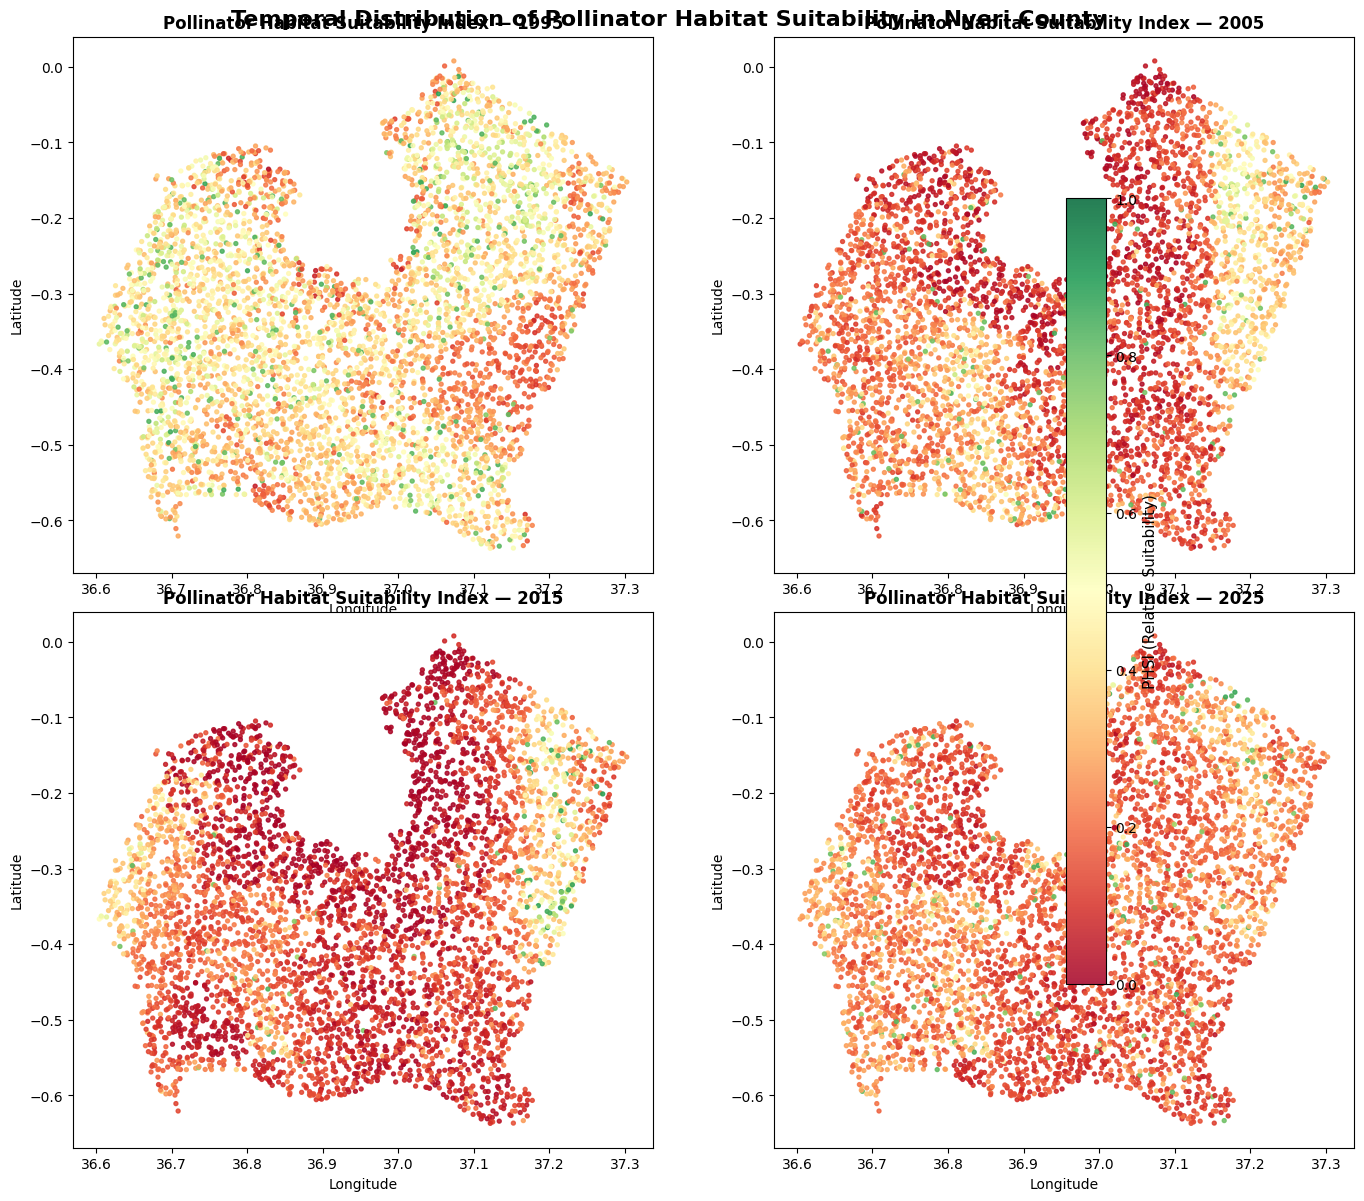

In [31]:
# ============================================================
# CELL 30 — FOUR-YEAR SPATIAL PHSI MAP
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 12)
)

years = [1995, 2005, 2015, 2025]

for ax, year in zip(axes.flat, years):

    year_data = phsi_data[
        phsi_data["year"] == year
    ]

    scatter = ax.scatter(
        year_data["Longitude"],
        year_data["Latitude"],
        c=year_data["PHSI"],
        cmap="RdYlGn",
        vmin=0,
        vmax=1,
        s=8,
        alpha=0.85
    )

    ax.set_title(
        f"Pollinator Habitat Suitability Index — {year}",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.set_aspect("equal")

# One common colorbar for all maps
cbar = fig.colorbar(
    scatter,
    ax=axes.ravel().tolist(),
    shrink=0.85,
    pad=0.02
)

cbar.set_label(
    "PHSI (Relative Suitability)",
    fontsize=11
)

fig.suptitle(
    "Temporal Distribution of Pollinator Habitat Suitability in Nyeri County",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

plt.tight_layout()

plt.show()

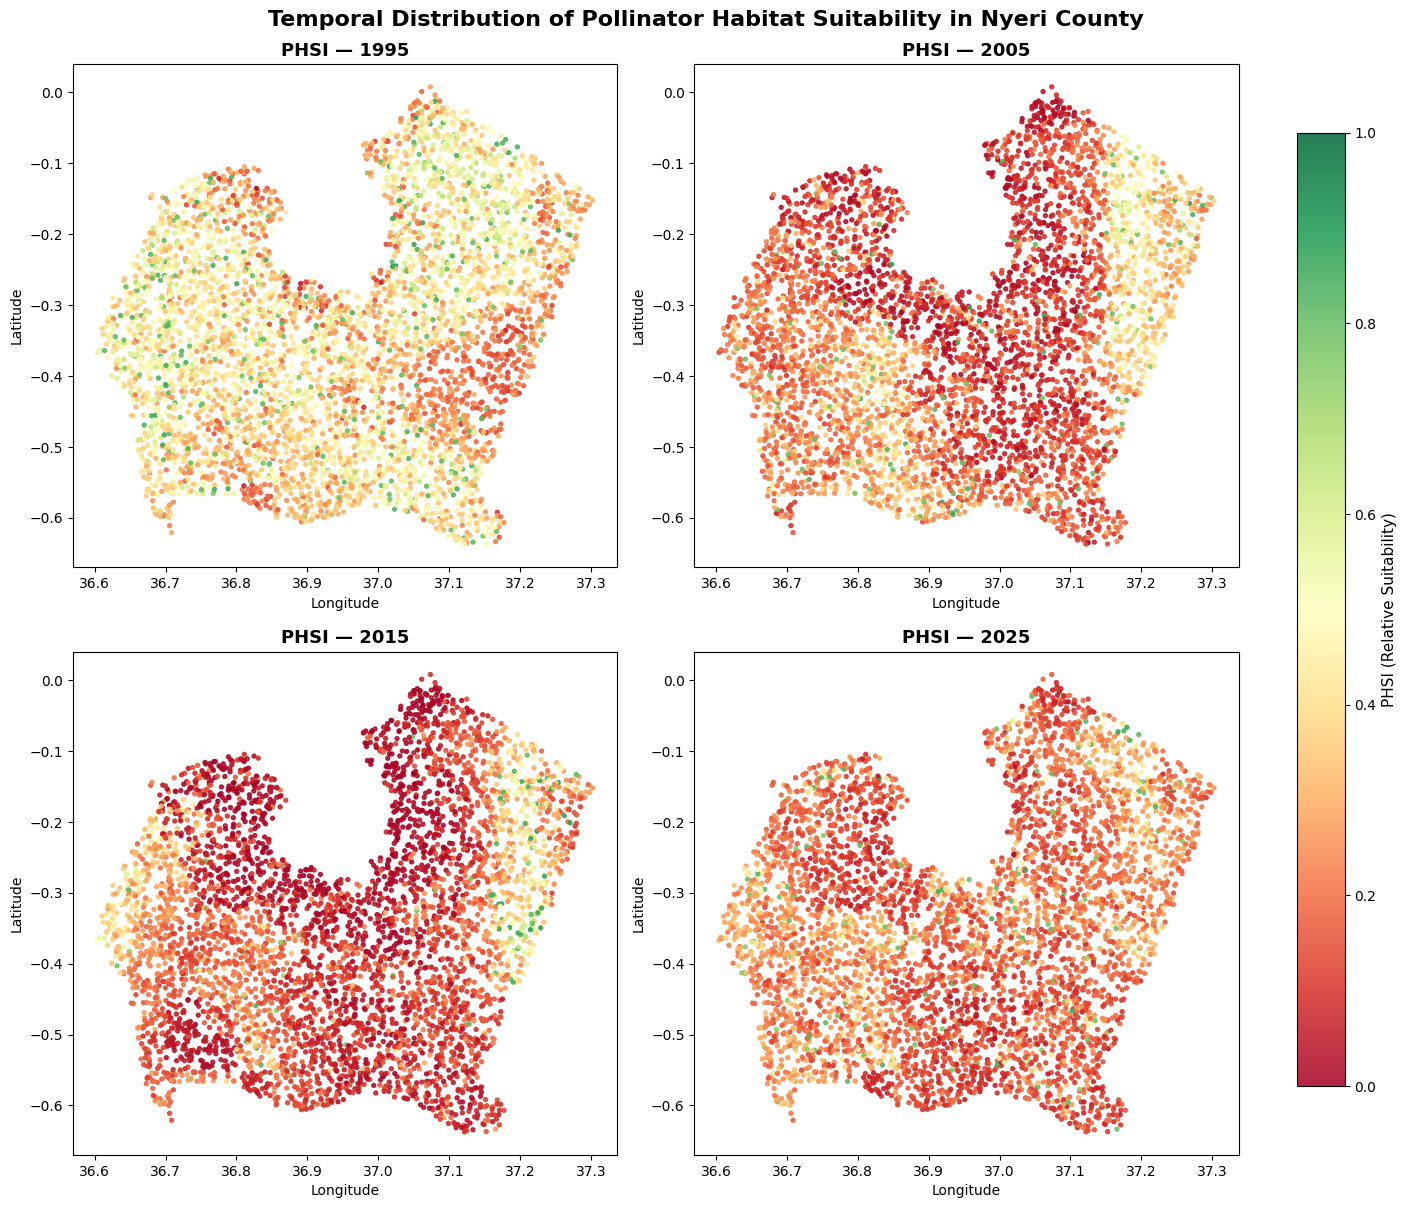

In [32]:
# ============================================================
# CELL 30 — FOUR-YEAR SPATIAL PHSI MAP (CLEAN VERSION)
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 12),
    constrained_layout=True
)

years = [1995, 2005, 2015, 2025]

for ax, year in zip(axes.flat, years):

    year_data = phsi_data[
        phsi_data["year"] == year
    ]

    scatter = ax.scatter(
        year_data["Longitude"],
        year_data["Latitude"],
        c=year_data["PHSI"],
        cmap="RdYlGn",
        vmin=0,
        vmax=1,
        s=8,
        alpha=0.85
    )

    ax.set_title(
        f"PHSI — {year}",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.set_aspect("equal")

# Common colorbar
cbar = fig.colorbar(
    scatter,
    ax=axes,
    shrink=0.85
)

cbar.set_label(
    "PHSI (Relative Suitability)",
    fontsize=11
)

fig.suptitle(
    "Temporal Distribution of Pollinator Habitat Suitability in Nyeri County",
    fontsize=16,
    fontweight="bold"
)

plt.show()

In [1]:
import rasterio

print("Rasterio version:", rasterio.__version__)

Rasterio version: 1.5.2


In [2]:
from pathlib import Path
import rasterio

# Modelling folder
raster_folder = Path(".")

# Find GeoTIFF files
raster_files = sorted(
    [f for f in raster_folder.iterdir()
     if f.suffix.lower() in [".tif", ".tiff"]]
)

print("Number of raster files found:", len(raster_files))
print("=" * 80)

for file in raster_files:
    with rasterio.open(file) as src:
        print(f"\n{file.name}")
        print("  CRS:", src.crs)
        print("  Size:", src.width, "x", src.height)
        print("  Pixel size:", src.res)
        print("  NoData:", src.nodata)
        print("  Bounds:", src.bounds)

Number of raster files found: 53

ASPECT.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Pixel size: (29.96982776157037, 29.96982776157036)
  NoData: None
  Bounds: BoundingBox(left=901190.2820161008, bottom=-71195.99519844058, right=979741.2005791768, top=2020.2940230758104)

LST_1995.tif
  CRS: EPSG:21097
  Size: 2622 x 2443
  Pixel size: (29.91144701645083, 29.911447016450737)
  NoData: None
  Bounds: BoundingBox(left=233192.94380732288, bottom=-71042.34228991558, right=311620.75788445695, top=2031.322771273568)

LST_2005.tif
  CRS: EPSG:21096
  Size: 2622 x 2444
  Pixel size: (29.96983007089559, 29.969830070895494)
  NoData: None
  Bounds: BoundingBox(left=901174.0506393221, bottom=-71210.94331160604, right=979754.9450852104, top=2035.3213816625503)

LST_2015.tif
  CRS: EPSG:21096
  Size: 2622 x 2444
  Pixel size: (29.96983007089559, 29.969830070895494)
  NoData: None
  Bounds: BoundingBox(left=901174.0506393221, bottom=-71210.94331160604, right=979754.9450852104, top=2035.321381662550

In [3]:
from pathlib import Path
import rasterio

raster_folder = Path(".")

for file in sorted(raster_folder.glob("*.tif")):
    with rasterio.open(file) as src:
        print(
            f"{file.name:30} "
            f"CRS={src.crs} | "
            f"SIZE={src.width}x{src.height} | "
            f"RES=({src.res[0]:.3f}, {src.res[1]:.3f})"
        )

ASPECT.tif                     CRS=EPSG:21096 | SIZE=2621x2443 | RES=(29.970, 29.970)
LST_1995.tif                   CRS=EPSG:21097 | SIZE=2622x2443 | RES=(29.911, 29.911)
LST_2005.tif                   CRS=EPSG:21096 | SIZE=2622x2444 | RES=(29.970, 29.970)
LST_2015.tif                   CRS=EPSG:21096 | SIZE=2622x2444 | RES=(29.970, 29.970)
LST_2025.tif                   CRS=EPSG:21096 | SIZE=2622x2444 | RES=(29.970, 29.970)
LULC_2005.tif                  CRS=EPSG:21096 | SIZE=2622x2444 | RES=(29.970, 29.970)
LULC_2015.tif                  CRS=EPSG:21096 | SIZE=2622x2444 | RES=(29.970, 29.970)
LULC_2025.tif                  CRS=EPSG:21096 | SIZE=2622x2444 | RES=(29.970, 29.970)
NDBI_1995.tif                  CRS=EPSG:21096 | SIZE=2622x2444 | RES=(29.970, 29.970)
NDBI_2005.tif                  CRS=EPSG:21096 | SIZE=2622x2444 | RES=(29.970, 29.970)
NDBI_2015.tif                  CRS=EPSG:21096 | SIZE=2622x2444 | RES=(29.970, 29.970)
NDBI_2025.tif                  CRS=EPSG:21096 | SIZE=2

In [4]:
import rasterio
from pathlib import Path

reference_file = Path("ASPECT.tif")

with rasterio.open(reference_file) as src:
    print("REFERENCE GRID")
    print("=" * 60)
    print("File:", reference_file.name)
    print("CRS:", src.crs)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Pixel size:", src.res)
    print("Bounds:", src.bounds)
    print("Transform:")
    print(src.transform)

REFERENCE GRID
File: ASPECT.tif
CRS: EPSG:21096
Width: 2621
Height: 2443
Pixel size: (29.96982776157037, 29.96982776157036)
Bounds: BoundingBox(left=901190.2820161008, bottom=-71195.99519844058, right=979741.2005791768, top=2020.2940230758104)
Transform:
| 29.97, 0.00, 901190.28|
| 0.00,-29.97, 2020.29|
| 0.00, 0.00, 1.00|


In [5]:
import rasterio
from pathlib import Path

reference_file = Path("ASPECT.tif")

static_predictors = [
    "ASPECT.tif",
    "SLOPE.tif",
    "PH.tif",
    "SOC(%).tif",
    "TRI.tif",
    "TWI.tif"
]

with rasterio.open(reference_file) as ref:
    ref_crs = ref.crs
    ref_width = ref.width
    ref_height = ref.height
    ref_res = ref.res
    ref_bounds = ref.bounds

print("REFERENCE GRID")
print("=" * 80)
print(f"CRS: {ref_crs}")
print(f"Size: {ref_width} x {ref_height}")
print(f"Resolution: {ref_res}")
print(f"Bounds: {ref_bounds}")

print("\nSTATIC PREDICTORS")
print("=" * 80)

for filename in static_predictors:
    with rasterio.open(filename) as src:
        print(f"\n{filename}")
        print(f"  CRS:        {src.crs}")
        print(f"  Size:       {src.width} x {src.height}")
        print(f"  Resolution: {src.res}")
        print(f"  Same CRS:   {src.crs == ref_crs}")
        print(f"  Same size:  {src.width == ref_width and src.height == ref_height}")
        print(f"  Bounds:     {src.bounds}")

REFERENCE GRID
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)
Bounds: BoundingBox(left=901190.2820161008, bottom=-71195.99519844058, right=979741.2005791768, top=2020.2940230758104)

STATIC PREDICTORS

ASPECT.tif
  CRS:        EPSG:21096
  Size:       2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)
  Same CRS:   True
  Same size:  True
  Bounds:     BoundingBox(left=901190.2820161008, bottom=-71195.99519844058, right=979741.2005791768, top=2020.2940230758104)

SLOPE.tif
  CRS:        EPSG:21096
  Size:       2613 x 2451
  Resolution: (30.069791879529557, 29.872124273238647)
  Same CRS:   True
  Same size:  False
  Bounds:     BoundingBox(left=901185.9563201434, bottom=-71169.40416580052, right=979758.3225013542, top=2047.1724279074115)

PH.tif
  CRS:        EPSG:21096
  Size:       313 x 296
  Resolution: (256.231461690015, 263.8504355220934)
  Same CRS:   True
  Same size:  False
  Bounds:     BoundingBox(left=900360.3284304811, b

In [6]:
import rasterio
from rasterio.warp import reproject, Resampling
from pathlib import Path
import numpy as np

# Reference grid
reference_file = Path("ASPECT.tif")

# Folder for aligned copies
aligned_folder = Path("aligned_predictors")
aligned_folder.mkdir(exist_ok=True)

# Static predictors that need alignment
static_to_align = {
    "SLOPE.tif": "SLOPE_aligned.tif",
    "PH.tif": "PH_aligned.tif",
    "SOC(%).tif": "SOC_aligned.tif",
    "TWI.tif": "TWI_aligned.tif"
}

with rasterio.open(reference_file) as ref:
    ref_crs = ref.crs
    ref_transform = ref.transform
    ref_width = ref.width
    ref_height = ref.height

    for input_name, output_name in static_to_align.items():

        input_path = Path(input_name)
        output_path = aligned_folder / output_name

        with rasterio.open(input_path) as src:

            profile = src.profile.copy()
            profile.update({
                "crs": ref_crs,
                "transform": ref_transform,
                "width": ref_width,
                "height": ref_height,
                "dtype": "float32",
                "nodata": np.nan
            })

            with rasterio.open(output_path, "w", **profile) as dst:

                reproject(
                    source=rasterio.band(src, 1),
                    destination=rasterio.band(dst, 1),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    dst_transform=ref_transform,
                    dst_crs=ref_crs,
                    resampling=Resampling.bilinear,
                    dst_nodata=np.nan
                )

        print(f"Created: {output_path}")

print("\nStatic predictor alignment complete.")

Created: aligned_predictors\SLOPE_aligned.tif
Created: aligned_predictors\PH_aligned.tif
Created: aligned_predictors\SOC_aligned.tif
Created: aligned_predictors\TWI_aligned.tif

Static predictor alignment complete.


In [7]:
from pathlib import Path
import rasterio

reference_file = Path("ASPECT.tif")
aligned_folder = Path("aligned_predictors")

with rasterio.open(reference_file) as ref:
    print("REFERENCE")
    print("=" * 80)
    print("CRS:", ref.crs)
    print("Size:", ref.width, "x", ref.height)
    print("Resolution:", ref.res)
    print("Bounds:", ref.bounds)

print("\nALIGNED STATIC PREDICTORS")
print("=" * 80)

for file in sorted(aligned_folder.glob("*_aligned.tif")):
    with rasterio.open(file) as src:
        print(f"\n{file.name}")
        print("  CRS:", src.crs)
        print("  Size:", src.width, "x", src.height)
        print("  Resolution:", src.res)
        print("  Same CRS:", src.crs == ref.crs)
        print("  Same size:", src.width == ref.width and src.height == ref.height)
        print("  Same transform:", src.transform == ref.transform)

REFERENCE
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)
Bounds: BoundingBox(left=901190.2820161008, bottom=-71195.99519844058, right=979741.2005791768, top=2020.2940230758104)

ALIGNED STATIC PREDICTORS

PH_aligned.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)
  Same CRS: True
  Same size: True
  Same transform: True

SLOPE_aligned.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)
  Same CRS: True
  Same size: True
  Same transform: True

SOC_aligned.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)
  Same CRS: True
  Same size: True
  Same transform: True

TWI_aligned.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)
  Same CRS: True
  Same size: True
  Same transform: True


In [8]:
from pathlib import Path

# Files relevant to 1995
keywords_1995 = [
    "NDVI",
    "PCI",
    "LST",
    "POP",
    "rain",
    "LULC"
]

print("1995 PREDICTOR FILES")
print("=" * 80)

for file in sorted(Path(".").glob("*.tif")):
    name = file.name.upper()

    # Show files containing 1995 and one of our predictor keywords
    if "1995" in name and any(keyword.upper() in name for keyword in keywords_1995):
        print(file.name)

1995 PREDICTOR FILES
LST_1995.tif
NDVI_1995.tif
NYERI_NDVI_1995.tif
PCI_1995.tif
POP_1995.tif
rainfall_1995.tif


In [9]:
import rasterio
import numpy as np

ndvi1 = "NDVI_1995.tif"
ndvi2 = "NYERI_NDVI_1995.tif"

with rasterio.open(ndvi1) as src1, rasterio.open(ndvi2) as src2:
    arr1 = src1.read(1, masked=True)
    arr2 = src2.read(1, masked=True)

    print("NDVI_1995.tif")
    print("Shape:", arr1.shape)
    print("CRS:", src1.crs)
    print("Min:", arr1.min())
    print("Max:", arr1.max())

    print("\nNYERI_NDVI_1995.tif")
    print("Shape:", arr2.shape)
    print("CRS:", src2.crs)
    print("Min:", arr2.min())
    print("Max:", arr2.max())

    # Compare if dimensions match
    if arr1.shape == arr2.shape:
        difference = np.abs(arr1.filled(np.nan) - arr2.filled(np.nan))

        print("\nCOMPARISON")
        print("Same shape:", arr1.shape == arr2.shape)
        print("Maximum absolute difference:", np.nanmax(difference))
        print("Mean absolute difference:", np.nanmean(difference))
        print("Exactly identical:",
              np.allclose(
                  arr1.filled(np.nan),
                  arr2.filled(np.nan),
                  equal_nan=True
              ))
    else:
        print("\nThe two rasters have different dimensions.")

NDVI_1995.tif
Shape: (2443, 2622)
CRS: EPSG:21097
Min: -0.87447697
Max: 0.9766097

NYERI_NDVI_1995.tif
Shape: (2443, 2622)
CRS: EPSG:21097
Min: -0.37830797
Max: 0.94182545

COMPARISON
Same shape: True
Maximum absolute difference: 1.4508531
Mean absolute difference: 0.046104778
Exactly identical: False


In [10]:
import rasterio

reference = "ASPECT.tif"

files_1995 = [
    "NYERI_NDVI_1995.tif",
    "PCI_1995.tif",
    "LST_1995.tif",
    "POP_1995.tif",
    "rainfall_1995.tif",
    "LULC_1995.tif"
]

with rasterio.open(reference) as ref:
    print("REFERENCE GRID: ASPECT.tif")
    print("=" * 80)
    print("CRS:", ref.crs)
    print("Size:", ref.width, "x", ref.height)
    print("Resolution:", ref.res)
    print("Bounds:", ref.bounds)

print("\n1995 PREDICTORS")
print("=" * 80)

for file in files_1995:
    with rasterio.open(file) as src:
        print(f"\n{file}")
        print("  CRS:", src.crs)
        print("  Size:", src.width, "x", src.height)
        print("  Resolution:", src.res)
        print("  Same CRS:", src.crs == ref.crs)

REFERENCE GRID: ASPECT.tif
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)
Bounds: BoundingBox(left=901190.2820161008, bottom=-71195.99519844058, right=979741.2005791768, top=2020.2940230758104)

1995 PREDICTORS

NYERI_NDVI_1995.tif
  CRS: EPSG:21097
  Size: 2622 x 2443
  Resolution: (29.91144701645083, 29.911447016450737)
  Same CRS: False

PCI_1995.tif
  CRS: EPSG:21096
  Size: 787 x 734
  Resolution: (100.07019708110265, 100.08560705233675)
  Same CRS: True

LST_1995.tif
  CRS: EPSG:21097
  Size: 2622 x 2443
  Resolution: (29.91144701645083, 29.911447016450737)
  Same CRS: False

POP_1995.tif
  CRS: EPSG:21096
  Size: 787 x 734
  Resolution: (99.89944395611981, 99.89944395611924)
  Same CRS: True

rainfall_1995.tif
  CRS: EPSG:21097
  Size: 16 x 14
  Resolution: (5549.492996052977, 5549.492996052978)
  Same CRS: False


RasterioIOError: LULC_1995.tif: No such file or directory

In [14]:
from pathlib import Path

print("LULC FILES")
print("=" * 80)

lulc_files = sorted(Path(".").glob("*LULC*.tif"))

for file in lulc_files:
    print(file.name)

LULC FILES
LULC_2005.tif
LULC_2015.tif
LULC_2025.tif


In [16]:
from pathlib import Path

print("POSSIBLE 1995 LULC FILES")
print("=" * 80)

for file in sorted(Path(".").glob("*.tif")):
    name = file.name.lower()
    
    if "1995" in name or "lulc" in name or "land" in name:
        print(file.name)

POSSIBLE 1995 LULC FILES
LST_1995.tif
LULC_1995.tif
LULC_2005.tif
LULC_2015.tif
LULC_2025.tif
NDBI_1995.tif
NDMI_1995.tif
NDVI_1995.tif
NYERI_NDVI_1995.tif
PCI_1995.tif
POP_1995.tif
rainfall_1995.tif
SAVI-1995.tif
SMI_1995.tif
TCI_1995.tif
VHI_1995.tif


In [17]:
import rasterio

reference = "ASPECT.tif"

files_1995 = [
    "SOC(%) .tif",
    "ASPECT.tif",
    "SLOPE.tif",
    "PH.tif",
    "TRI.tif",
    "TWI.tif",
    "NYERI_NDVI_1995.tif",
    "PCI_1995.tif",
    "LST_1995.tif",
    "POP_1995.tif",
    "rainfall_1995.tif",
    "LULC_1995.tif"
]

with rasterio.open(reference) as ref:
    print("REFERENCE GRID")
    print("=" * 80)
    print("CRS:", ref.crs)
    print("Size:", ref.width, "x", ref.height)
    print("Resolution:", ref.res)

print("\n1995 PREDICTORS")
print("=" * 80)

for file in files_1995:
    try:
        with rasterio.open(file) as src:
            print(f"\n{file}")
            print("  CRS:", src.crs)
            print("  Size:", src.width, "x", src.height)
            print("  Resolution:", src.res)
    except Exception as e:
        print(f"\nERROR: {file}")
        print(e)

REFERENCE GRID
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)

1995 PREDICTORS

ERROR: SOC(%) .tif
SOC(%) .tif: No such file or directory

ASPECT.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)

SLOPE.tif
  CRS: EPSG:21096
  Size: 2613 x 2451
  Resolution: (30.069791879529557, 29.872124273238647)

PH.tif
  CRS: EPSG:21096
  Size: 313 x 296
  Resolution: (256.231461690015, 263.8504355220934)

TRI.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)

TWI.tif
  CRS: EPSG:21096
  Size: 170 x 159
  Resolution: (463.36363975738027, 463.3636397573804)

NYERI_NDVI_1995.tif
  CRS: EPSG:21097
  Size: 2622 x 2443
  Resolution: (29.91144701645083, 29.911447016450737)

PCI_1995.tif
  CRS: EPSG:21096
  Size: 787 x 734
  Resolution: (100.07019708110265, 100.08560705233675)

LST_1995.tif
  CRS: EPSG:21097
  Size: 2622 x 2443
  Resolution: (29.91144701645083, 29.911447016450737

In [18]:
from pathlib import Path

print("SOC FILES")
print("=" * 80)

for file in sorted(Path(".").glob("*SOC*.tif")):
    print(file.name)

SOC FILES
SOC(%).tif


In [19]:
import rasterio
from rasterio.warp import reproject, Resampling
from pathlib import Path
import numpy as np

# ------------------------------------------------------------
# Reference grid
# ------------------------------------------------------------
reference_file = "ASPECT.tif"
output_dir = Path("aligned_predictors")
output_dir.mkdir(exist_ok=True)

with rasterio.open(reference_file) as ref:
    ref_crs = ref.crs
    ref_transform = ref.transform
    ref_width = ref.width
    ref_height = ref.height

# ------------------------------------------------------------
# 1995 predictors
# ------------------------------------------------------------
predictors_1995 = {
    "SOC": ("SOC(%).tif", Resampling.bilinear),
    "Aspect": ("ASPECT.tif", Resampling.bilinear),
    "Slope": ("SLOPE.tif", Resampling.bilinear),
    "PH": ("PH.tif", Resampling.bilinear),
    "TRI": ("TRI.tif", Resampling.bilinear),
    "TWI": ("TWI.tif", Resampling.bilinear),
    "NDVI": ("NYERI_NDVI_1995.tif", Resampling.bilinear),
    "PCI": ("PCI_1995.tif", Resampling.bilinear),
    "LST": ("LST_1995.tif", Resampling.bilinear),
    "pop": ("POP_1995.tif", Resampling.bilinear),
    "rain": ("rainfall_1995.tif", Resampling.bilinear),
    "LULC": ("LULC_1995.tif", Resampling.nearest)
}

print("ALIGNING 1995 PREDICTORS")
print("=" * 80)

for predictor, (input_file, resampling_method) in predictors_1995.items():

    output_file = output_dir / f"{predictor}_1995_aligned.tif"

    with rasterio.open(input_file) as src:

        # Create destination array
        destination = np.full(
            (ref_height, ref_width),
            np.nan,
            dtype="float32"
        )

        reproject(
            source=rasterio.band(src, 1),
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            src_nodata=src.nodata,
            dst_nodata=np.nan,
            resampling=resampling_method
        )

        profile = src.profile.copy()

        profile.update({
            "driver": "GTiff",
            "height": ref_height,
            "width": ref_width,
            "crs": ref_crs,
            "transform": ref_transform,
            "dtype": "float32",
            "count": 1,
            "nodata": np.nan,
            "compress": "lzw"
        })

        with rasterio.open(output_file, "w", **profile) as dst:
            dst.write(destination, 1)

    print(f"✓ {predictor}: {output_file}")

print("\n1995 alignment complete.")

ALIGNING 1995 PREDICTORS
✓ SOC: aligned_predictors\SOC_1995_aligned.tif
✓ Aspect: aligned_predictors\Aspect_1995_aligned.tif
✓ Slope: aligned_predictors\Slope_1995_aligned.tif
✓ PH: aligned_predictors\PH_1995_aligned.tif
✓ TRI: aligned_predictors\TRI_1995_aligned.tif
✓ TWI: aligned_predictors\TWI_1995_aligned.tif
✓ NDVI: aligned_predictors\NDVI_1995_aligned.tif
✓ PCI: aligned_predictors\PCI_1995_aligned.tif
✓ LST: aligned_predictors\LST_1995_aligned.tif
✓ pop: aligned_predictors\pop_1995_aligned.tif
✓ rain: aligned_predictors\rain_1995_aligned.tif
✓ LULC: aligned_predictors\LULC_1995_aligned.tif

1995 alignment complete.


In [20]:
import rasterio
from pathlib import Path
import numpy as np

aligned_1995 = sorted(
    Path("aligned_predictors").glob("*_1995_aligned.tif")
)

print("1995 ALIGNED PREDICTOR QUALITY CHECK")
print("=" * 80)

reference = "ASPECT.tif"

with rasterio.open(reference) as ref:
    ref_crs = ref.crs
    ref_width = ref.width
    ref_height = ref.height
    ref_transform = ref.transform

    print("REFERENCE")
    print("CRS:", ref_crs)
    print("Size:", ref_width, "x", ref_height)
    print()

all_good = True

for file in aligned_1995:
    with rasterio.open(file) as src:
        same_crs = src.crs == ref_crs
        same_size = (src.width == ref_width and src.height == ref_height)
        same_transform = src.transform == ref_transform

        arr = src.read(1, masked=True)

        print(file.name)
        print("  CRS:", src.crs, "✓" if same_crs else "✗")
        print("  Size:", src.width, "x", src.height, "✓" if same_size else "✗")
        print("  Same grid:", same_transform, "✓" if same_transform else "✗")
        print("  Valid pixels:", int(np.sum(~arr.mask)))
        
        if not (same_crs and same_size and same_transform):
            all_good = False

print("\n" + "=" * 80)

if all_good:
    print("✓ ALL 1995 RASTERS MATCH THE REFERENCE GRID")
else:
    print("✗ CHECK REQUIRED — ONE OR MORE RASTERS DO NOT MATCH")

1995 ALIGNED PREDICTOR QUALITY CHECK
REFERENCE
CRS: EPSG:21096
Size: 2621 x 2443

Aspect_1995_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
LST_1995_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6400478
LULC_1995_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 3733178
NDVI_1995_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6400478
PCI_1995_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
PH_1995_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
pop_1995_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
rain_1995_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
Slope_1995_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x

In [21]:
import rasterio

files_2005 = [
    "SOC(%) .tif",
    "ASPECT.tif",
    "SLOPE.tif",
    "PH.tif",
    "TRI.tif",
    "TWI.tif",
    "NDVI_2005.tif",
    "PCI_2005_SMOOTH.tif",
    "LST_2005.tif",
    "POP_2005.tif",
    "rainfall_2005.tif",
    "LULC_2005.tif"
]

reference = "ASPECT.tif"

with rasterio.open(reference) as ref:
    print("REFERENCE GRID")
    print("=" * 80)
    print("CRS:", ref.crs)
    print("Size:", ref.width, "x", ref.height)
    print("Resolution:", ref.res)

print("\n2005 PREDICTORS")
print("=" * 80)

for file in files_2005:
    try:
        with rasterio.open(file) as src:
            print(f"\n{file}")
            print("  CRS:", src.crs)
            print("  Size:", src.width, "x", src.height)
            print("  Resolution:", src.res)
    except Exception as e:
        print(f"\nERROR: {file}")
        print(e)

REFERENCE GRID
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)

2005 PREDICTORS

ERROR: SOC(%) .tif
SOC(%) .tif: No such file or directory

ASPECT.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)

SLOPE.tif
  CRS: EPSG:21096
  Size: 2613 x 2451
  Resolution: (30.069791879529557, 29.872124273238647)

PH.tif
  CRS: EPSG:21096
  Size: 313 x 296
  Resolution: (256.231461690015, 263.8504355220934)

TRI.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)

TWI.tif
  CRS: EPSG:21096
  Size: 170 x 159
  Resolution: (463.36363975738027, 463.3636397573804)

NDVI_2005.tif
  CRS: EPSG:21096
  Size: 2622 x 2444
  Resolution: (29.96983007089559, 29.969830070895494)

PCI_2005_SMOOTH.tif
  CRS: EPSG:21096
  Size: 787 x 734
  Resolution: (100.07019708110265, 100.08560705233675)

LST_2005.tif
  CRS: EPSG:21096
  Size: 2622 x 2444
  Resolution: (29.96983007089559, 29.96983007089549

In [23]:
from pathlib import Path

print("RAINFALL FILES")
print("=" * 80)

for file in sorted(Path(".").glob("*rain*.tif")):
    print(file.name)

RAINFALL FILES
rainfall_1995.tif
rainfall_2005.tif
rainfall_2015.tif
rainfall_2025.tif


ALIGNING 2005 PREDICTORS
✓ SOC: aligned_predictors\SOC_2005_aligned.tif
✓ Aspect: aligned_predictors\Aspect_2005_aligned.tif
✓ Slope: aligned_predictors\Slope_2005_aligned.tif
✓ PH: aligned_predictors\PH_2005_aligned.tif
✓ TRI: aligned_predictors\TRI_2005_aligned.tif
✓ TWI: aligned_predictors\TWI_2005_aligned.tif
✓ NDVI: aligned_predictors\NDVI_2005_aligned.tif
✓ PCI: aligned_predictors\PCI_2005_aligned.tif
✓ LST: aligned_predictors\LST_2005_aligned.tif
✓ pop: aligned_predictors\pop_2005_aligned.tif
✓ rain: aligned_predictors\rain_2005_aligned.tif
✓ LULC: aligned_predictors\LULC_2005_aligned.tif

2005 alignment complete.


In [25]:
import rasterio
from pathlib import Path
import numpy as np

reference = "ASPECT.tif"

aligned_2005 = sorted(
    Path("aligned_predictors").glob("*_2005_aligned.tif")
)

print("2005 ALIGNED PREDICTOR QUALITY CHECK")
print("=" * 80)

with rasterio.open(reference) as ref:
    ref_crs = ref.crs
    ref_width = ref.width
    ref_height = ref.height
    ref_transform = ref.transform

    print("REFERENCE")
    print("CRS:", ref_crs)
    print("Size:", ref_width, "x", ref_height)
    print()

all_good = True

for file in aligned_2005:
    with rasterio.open(file) as src:
        same_crs = src.crs == ref_crs
        same_size = (src.width == ref_width and src.height == ref_height)
        same_transform = src.transform == ref_transform

        arr = src.read(1, masked=True)

        print(file.name)
        print("  CRS:", src.crs, "✓" if same_crs else "✗")
        print("  Size:", src.width, "x", src.height, "✓" if same_size else "✗")
        print("  Same grid:", same_transform, "✓" if same_transform else "✗")
        print("  Valid pixels:", int(np.sum(~arr.mask)))

        if not (same_crs and same_size and same_transform):
            all_good = False

print("\n" + "=" * 80)

if all_good:
    print("✓ ALL 2005 RASTERS MATCH THE REFERENCE GRID")
else:
    print("✗ CHECK REQUIRED — ONE OR MORE RASTERS DO NOT MATCH")

2005 ALIGNED PREDICTOR QUALITY CHECK
REFERENCE
CRS: EPSG:21096
Size: 2621 x 2443

Aspect_2005_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
LST_2005_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
LULC_2005_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 3722494
NDVI_2005_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
PCI_2005_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
PH_2005_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
pop_2005_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6402825
rain_2005_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 3743725
Slope_2005_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x

In [26]:
import rasterio

files_2015 = [
    "SOC(%).tif",
    "ASPECT.tif",
    "SLOPE.tif",
    "PH.tif",
    "TRI.tif",
    "TWI.tif",
    "NDVI_2015.tif",
    "PCI_2015.tif",
    "LST_2015.tif",
    "POP_2015_NEW.tif",
    "rainfall_2015.tif",
    "LULC_2015.tif"
]

reference = "ASPECT.tif"

with rasterio.open(reference) as ref:
    print("REFERENCE GRID")
    print("=" * 80)
    print("CRS:", ref.crs)
    print("Size:", ref.width, "x", ref.height)
    print("Resolution:", ref.res)

print("\n2015 PREDICTORS")
print("=" * 80)

for file in files_2015:
    try:
        with rasterio.open(file) as src:
            print(f"\n{file}")
            print("  CRS:", src.crs)
            print("  Size:", src.width, "x", src.height)
            print("  Resolution:", src.res)
    except Exception as e:
        print(f"\nERROR: {file}")
        print(e)

REFERENCE GRID
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)

2015 PREDICTORS

SOC(%).tif
  CRS: EPSG:21096
  Size: 316 x 295
  Resolution: (249.74907365385104, 249.7490736538504)

ASPECT.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)

SLOPE.tif
  CRS: EPSG:21096
  Size: 2613 x 2451
  Resolution: (30.069791879529557, 29.872124273238647)

PH.tif
  CRS: EPSG:21096
  Size: 313 x 296
  Resolution: (256.231461690015, 263.8504355220934)

TRI.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)

TWI.tif
  CRS: EPSG:21096
  Size: 170 x 159
  Resolution: (463.36363975738027, 463.3636397573804)

NDVI_2015.tif
  CRS: EPSG:21096
  Size: 2622 x 2444
  Resolution: (29.96983007089559, 29.969830070895494)

PCI_2015.tif
  CRS: EPSG:21096
  Size: 788 x 735
  Resolution: (100.1404247220823, 100.17145251715128)

LST_2015.tif
  CRS: EPSG:21096
  Size: 2622 x 2444
  Resolution: (2

In [27]:
import rasterio
from rasterio.warp import reproject, Resampling
from pathlib import Path
import numpy as np

# ------------------------------------------------------------
# Reference grid
# ------------------------------------------------------------
reference_file = "ASPECT.tif"
output_dir = Path("aligned_predictors")
output_dir.mkdir(exist_ok=True)

with rasterio.open(reference_file) as ref:
    ref_crs = ref.crs
    ref_transform = ref.transform
    ref_width = ref.width
    ref_height = ref.height

# ------------------------------------------------------------
# 2015 predictors
# ------------------------------------------------------------
predictors_2015 = {
    "SOC": ("SOC(%).tif", Resampling.bilinear),
    "Aspect": ("ASPECT.tif", Resampling.bilinear),
    "Slope": ("SLOPE.tif", Resampling.bilinear),
    "PH": ("PH.tif", Resampling.bilinear),
    "TRI": ("TRI.tif", Resampling.bilinear),
    "TWI": ("TWI.tif", Resampling.bilinear),
    "NDVI": ("NDVI_2015.tif", Resampling.bilinear),
    "PCI": ("PCI_2015.tif", Resampling.bilinear),
    "LST": ("LST_2015.tif", Resampling.bilinear),
    "pop": ("POP_2015_NEW.tif", Resampling.bilinear),
    "rain": ("rainfall_2015.tif", Resampling.bilinear),
    "LULC": ("LULC_2015.tif", Resampling.nearest)
}

print("ALIGNING 2015 PREDICTORS")
print("=" * 80)

for predictor, (input_file, resampling_method) in predictors_2015.items():

    output_file = output_dir / f"{predictor}_2015_aligned.tif"

    with rasterio.open(input_file) as src:

        destination = np.full(
            (ref_height, ref_width),
            np.nan,
            dtype="float32"
        )

        reproject(
            source=rasterio.band(src, 1),
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            src_nodata=src.nodata,
            dst_nodata=np.nan,
            resampling=resampling_method
        )

        profile = src.profile.copy()

        profile.update({
            "driver": "GTiff",
            "height": ref_height,
            "width": ref_width,
            "crs": ref_crs,
            "transform": ref_transform,
            "dtype": "float32",
            "count": 1,
            "nodata": np.nan,
            "compress": "lzw"
        })

        with rasterio.open(output_file, "w", **profile) as dst:
            dst.write(destination, 1)

    print(f"✓ {predictor}: {output_file}")

print("\n2015 alignment complete.")

ALIGNING 2015 PREDICTORS
✓ SOC: aligned_predictors\SOC_2015_aligned.tif
✓ Aspect: aligned_predictors\Aspect_2015_aligned.tif
✓ Slope: aligned_predictors\Slope_2015_aligned.tif
✓ PH: aligned_predictors\PH_2015_aligned.tif
✓ TRI: aligned_predictors\TRI_2015_aligned.tif
✓ TWI: aligned_predictors\TWI_2015_aligned.tif
✓ NDVI: aligned_predictors\NDVI_2015_aligned.tif
✓ PCI: aligned_predictors\PCI_2015_aligned.tif
✓ LST: aligned_predictors\LST_2015_aligned.tif
✓ pop: aligned_predictors\pop_2015_aligned.tif
✓ rain: aligned_predictors\rain_2015_aligned.tif
✓ LULC: aligned_predictors\LULC_2015_aligned.tif

2015 alignment complete.


In [28]:
import rasterio
from pathlib import Path
import numpy as np

reference = "ASPECT.tif"

aligned_2015 = sorted(
    Path("aligned_predictors").glob("*_2015_aligned.tif")
)

print("2015 ALIGNED PREDICTOR QUALITY CHECK")
print("=" * 80)

with rasterio.open(reference) as ref:
    ref_crs = ref.crs
    ref_width = ref.width
    ref_height = ref.height
    ref_transform = ref.transform

    print("REFERENCE")
    print("CRS:", ref_crs)
    print("Size:", ref_width, "x", ref_height)
    print()

all_good = True

for file in aligned_2015:
    with rasterio.open(file) as src:
        same_crs = src.crs == ref_crs
        same_size = (src.width == ref_width and src.height == ref_height)
        same_transform = src.transform == ref_transform

        arr = src.read(1, masked=True)

        print(file.name)
        print("  CRS:", src.crs, "✓" if same_crs else "✗")
        print("  Size:", src.width, "x", src.height, "✓" if same_size else "✗")
        print("  Same grid:", same_transform, "✓" if same_transform else "✗")
        print("  Valid pixels:", int(np.sum(~arr.mask)))

        if not (same_crs and same_size and same_transform):
            all_good = False

print("\n" + "=" * 80)

if all_good:
    print("✓ ALL 2015 RASTERS MATCH THE REFERENCE GRID")
else:
    print("✗ CHECK REQUIRED — ONE OR MORE RASTERS DO NOT MATCH")

2015 ALIGNED PREDICTOR QUALITY CHECK
REFERENCE
CRS: EPSG:21096
Size: 2621 x 2443

Aspect_2015_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
LST_2015_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
LULC_2015_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 3732029
NDVI_2015_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
PCI_2015_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
PH_2015_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
pop_2015_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6402825
rain_2015_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 3743725
Slope_2015_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x

In [29]:
import rasterio

files_2025 = [
    "SOC(%).tif",
    "ASPECT.tif",
    "SLOPE.tif",
    "PH.tif",
    "TRI.tif",
    "TWI.tif",
    "NDVI_2025.tif",
    "PCI_2025.tif",
    "LST_2025.tif",
    "POP_2025.tif",
    "rainfall_2025.tif",
    "LULC_2025.tif"
]

reference = "ASPECT.tif"

with rasterio.open(reference) as ref:
    print("REFERENCE GRID")
    print("=" * 80)
    print("CRS:", ref.crs)
    print("Size:", ref.width, "x", ref.height)
    print("Resolution:", ref.res)

print("\n2025 PREDICTORS")
print("=" * 80)

for file in files_2025:
    try:
        with rasterio.open(file) as src:
            print(f"\n{file}")
            print("  CRS:", src.crs)
            print("  Size:", src.width, "x", src.height)
            print("  Resolution:", src.res)
    except Exception as e:
        print(f"\nERROR: {file}")
        print(e)

REFERENCE GRID
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)

2025 PREDICTORS

SOC(%).tif
  CRS: EPSG:21096
  Size: 316 x 295
  Resolution: (249.74907365385104, 249.7490736538504)

ASPECT.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)

SLOPE.tif
  CRS: EPSG:21096
  Size: 2613 x 2451
  Resolution: (30.069791879529557, 29.872124273238647)

PH.tif
  CRS: EPSG:21096
  Size: 313 x 296
  Resolution: (256.231461690015, 263.8504355220934)

TRI.tif
  CRS: EPSG:21096
  Size: 2621 x 2443
  Resolution: (29.96982776157037, 29.96982776157036)

TWI.tif
  CRS: EPSG:21096
  Size: 170 x 159
  Resolution: (463.36363975738027, 463.3636397573804)

NDVI_2025.tif
  CRS: EPSG:21096
  Size: 2614 x 2452
  Resolution: (30.06978913671304, 29.87212477542334)

PCI_2025.tif
  CRS: EPSG:21096
  Size: 787 x 734
  Resolution: (100.07019708110265, 100.08560705233675)

LST_2025.tif
  CRS: EPSG:21096
  Size: 2622 x 2444
  Resolution: (2

In [30]:
import rasterio
from rasterio.warp import reproject, Resampling
from pathlib import Path
import numpy as np

# ------------------------------------------------------------
# Reference grid
# ------------------------------------------------------------
reference_file = "ASPECT.tif"
output_dir = Path("aligned_predictors")
output_dir.mkdir(exist_ok=True)

with rasterio.open(reference_file) as ref:
    ref_crs = ref.crs
    ref_transform = ref.transform
    ref_width = ref.width
    ref_height = ref.height

# ------------------------------------------------------------
# 2025 predictors
# ------------------------------------------------------------
predictors_2025 = {
    "SOC": ("SOC(%).tif", Resampling.bilinear),
    "Aspect": ("ASPECT.tif", Resampling.bilinear),
    "Slope": ("SLOPE.tif", Resampling.bilinear),
    "PH": ("PH.tif", Resampling.bilinear),
    "TRI": ("TRI.tif", Resampling.bilinear),
    "TWI": ("TWI.tif", Resampling.bilinear),
    "NDVI": ("NDVI_2025.tif", Resampling.bilinear),
    "PCI": ("PCI_2025.tif", Resampling.bilinear),
    "LST": ("LST_2025.tif", Resampling.bilinear),
    "pop": ("POP_2025.tif", Resampling.bilinear),
    "rain": ("rainfall_2025.tif", Resampling.bilinear),
    "LULC": ("LULC_2025.tif", Resampling.nearest)
}

print("ALIGNING 2025 PREDICTORS")
print("=" * 80)

for predictor, (input_file, resampling_method) in predictors_2025.items():

    output_file = output_dir / f"{predictor}_2025_aligned.tif"

    with rasterio.open(input_file) as src:

        destination = np.full(
            (ref_height, ref_width),
            np.nan,
            dtype="float32"
        )

        reproject(
            source=rasterio.band(src, 1),
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            src_nodata=src.nodata,
            dst_nodata=np.nan,
            resampling=resampling_method
        )

        profile = src.profile.copy()

        profile.update({
            "driver": "GTiff",
            "height": ref_height,
            "width": ref_width,
            "crs": ref_crs,
            "transform": ref_transform,
            "dtype": "float32",
            "count": 1,
            "nodata": np.nan,
            "compress": "lzw"
        })

        with rasterio.open(output_file, "w", **profile) as dst:
            dst.write(destination, 1)

    print(f"✓ {predictor}: {output_file}")

print("\n2025 alignment complete.")

ALIGNING 2025 PREDICTORS
✓ SOC: aligned_predictors\SOC_2025_aligned.tif
✓ Aspect: aligned_predictors\Aspect_2025_aligned.tif
✓ Slope: aligned_predictors\Slope_2025_aligned.tif
✓ PH: aligned_predictors\PH_2025_aligned.tif
✓ TRI: aligned_predictors\TRI_2025_aligned.tif
✓ TWI: aligned_predictors\TWI_2025_aligned.tif
✓ NDVI: aligned_predictors\NDVI_2025_aligned.tif
✓ PCI: aligned_predictors\PCI_2025_aligned.tif
✓ LST: aligned_predictors\LST_2025_aligned.tif
✓ pop: aligned_predictors\pop_2025_aligned.tif
✓ rain: aligned_predictors\rain_2025_aligned.tif
✓ LULC: aligned_predictors\LULC_2025_aligned.tif

2025 alignment complete.


In [31]:
import rasterio
from pathlib import Path
import numpy as np

reference = "ASPECT.tif"

aligned_2025 = sorted(
    Path("aligned_predictors").glob("*_2025_aligned.tif")
)

print("2025 ALIGNED PREDICTOR QUALITY CHECK")
print("=" * 80)

with rasterio.open(reference) as ref:
    ref_crs = ref.crs
    ref_width = ref.width
    ref_height = ref.height
    ref_transform = ref.transform

    print("REFERENCE")
    print("CRS:", ref_crs)
    print("Size:", ref_width, "x", ref_height)
    print()

all_good = True

for file in aligned_2025:
    with rasterio.open(file) as src:
        same_crs = src.crs == ref_crs
        same_size = (src.width == ref_width and src.height == ref_height)
        same_transform = src.transform == ref_transform

        arr = src.read(1, masked=True)

        print(file.name)
        print("  CRS:", src.crs, "✓" if same_crs else "✗")
        print("  Size:", src.width, "x", src.height, "✓" if same_size else "✗")
        print("  Same grid:", same_transform, "✓" if same_transform else "✗")
        print("  Valid pixels:", int(np.sum(~arr.mask)))

        if not (same_crs and same_size and same_transform):
            all_good = False

print("\n" + "=" * 80)

if all_good:
    print("✓ ALL 2025 RASTERS MATCH THE REFERENCE GRID")
else:
    print("✗ CHECK REQUIRED — ONE OR MORE RASTERS DO NOT MATCH")

2025 ALIGNED PREDICTOR QUALITY CHECK
REFERENCE
CRS: EPSG:21096
Size: 2621 x 2443

Aspect_2025_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
LST_2025_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
LULC_2025_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 3729170
NDVI_2025_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
PCI_2025_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
PH_2025_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6403103
pop_2025_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 6402807
rain_2025_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x 2443 ✓
  Same grid: True ✓
  Valid pixels: 3739537
Slope_2025_aligned.tif
  CRS: EPSG:21096 ✓
  Size: 2621 x

In [32]:
from pathlib import Path
import rasterio
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# PHSI RASTER PREDICTION SETUP
# ------------------------------------------------------------

aligned_dir = Path("aligned_predictors")
output_dir = Path("PHSI_outputs")
output_dir.mkdir(exist_ok=True)

# Exact predictor order used by the final RF model
mapping_predictors = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "LST",
    "pop",
    "rain",
    "LULC"
]

years = [1995, 2005, 2015, 2025]

print("PHSI RASTER PREDICTION SETUP")
print("=" * 70)

print("Output folder:", output_dir)
print("Years:", years)
print("Number of predictors:", len(mapping_predictors))

print("\nPredictor order:")
for i, predictor in enumerate(mapping_predictors, start=1):
    print(f"{i:2d}. {predictor}")

# Check that every required aligned raster exists
print("\nChecking aligned predictor files...")

all_files_exist = True

for year in years:
    print(f"\n{year}:")
    
    for predictor in mapping_predictors:
        file_path = aligned_dir / f"{predictor}_{year}_aligned.tif"
        
        if file_path.exists():
            print(f"  ✓ {file_path.name}")
        else:
            print(f"  ✗ MISSING: {file_path.name}")
            all_files_exist = False

print("\n" + "=" * 70)

if all_files_exist:
    print("✓ ALL REQUIRED PREDICTOR RASTERS ARE AVAILABLE")
    print("✓ READY FOR SPATIAL RF PREDICTION")
else:
    print("✗ SOME REQUIRED FILES ARE MISSING")

PHSI RASTER PREDICTION SETUP
Output folder: PHSI_outputs
Years: [1995, 2005, 2015, 2025]
Number of predictors: 12

Predictor order:
 1. SOC
 2. Aspect
 3. Slope
 4. PH
 5. TRI
 6. TWI
 7. NDVI
 8. PCI
 9. LST
10. pop
11. rain
12. LULC

Checking aligned predictor files...

1995:
  ✓ SOC_1995_aligned.tif
  ✓ Aspect_1995_aligned.tif
  ✓ Slope_1995_aligned.tif
  ✓ PH_1995_aligned.tif
  ✓ TRI_1995_aligned.tif
  ✓ TWI_1995_aligned.tif
  ✓ NDVI_1995_aligned.tif
  ✓ PCI_1995_aligned.tif
  ✓ LST_1995_aligned.tif
  ✓ pop_1995_aligned.tif
  ✓ rain_1995_aligned.tif
  ✓ LULC_1995_aligned.tif

2005:
  ✓ SOC_2005_aligned.tif
  ✓ Aspect_2005_aligned.tif
  ✓ Slope_2005_aligned.tif
  ✓ PH_2005_aligned.tif
  ✓ TRI_2005_aligned.tif
  ✓ TWI_2005_aligned.tif
  ✓ NDVI_2005_aligned.tif
  ✓ PCI_2005_aligned.tif
  ✓ LST_2005_aligned.tif
  ✓ pop_2005_aligned.tif
  ✓ rain_2005_aligned.tif
  ✓ LULC_2005_aligned.tif

2015:
  ✓ SOC_2015_aligned.tif
  ✓ Aspect_2015_aligned.tif
  ✓ Slope_2015_aligned.tif
  ✓ PH_2015_a

In [33]:
from pathlib import Path
import rasterio
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# GENERATE 1995 PHSI RASTER USING FINAL RANDOM FOREST
# ------------------------------------------------------------

year = 1995

aligned_dir = Path("aligned_predictors")
output_dir = Path("PHSI_outputs")
output_file = output_dir / f"PHSI_{year}.tif"

# Exact predictor order used during model training
mapping_predictors = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "LST",
    "pop",
    "rain",
    "LULC"
]

# ------------------------------------------------------------
# Open all predictor rasters
# ------------------------------------------------------------

files = {
    predictor: rasterio.open(
        aligned_dir / f"{predictor}_{year}_aligned.tif"
    )
    for predictor in mapping_predictors
}

# Use first raster as spatial reference
reference = files["SOC"]

height = reference.height
width = reference.width

print(f"GENERATING PHSI RASTER — {year}")
print("=" * 70)
print("Raster size:", width, "x", height)
print("Total pixels:", f"{width * height:,}")
print("Predictors:", len(mapping_predictors))
print()

# ------------------------------------------------------------
# Prepare output raster
# ------------------------------------------------------------

profile = reference.profile.copy()

profile.update({
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": "float32",
    "nodata": np.nan,
    "compress": "lzw"
})

# ------------------------------------------------------------
# Predict in raster windows
# ------------------------------------------------------------

total_valid = 0
total_nodata = 0
window_count = 0

with rasterio.open(output_file, "w", **profile) as dst:

    for _, window in reference.block_windows(1):

        # ----------------------------------------------------
        # Read predictor values for this window
        # ----------------------------------------------------
        
        arrays = []

        for predictor in mapping_predictors:
            arr = files[predictor].read(1, window=window).astype("float32")
            arrays.append(arr)

        # ----------------------------------------------------
        # Identify pixels where ALL predictors are valid
        # ----------------------------------------------------
        
        valid_mask = np.ones(arrays[0].shape, dtype=bool)

        for arr in arrays:
            valid_mask &= np.isfinite(arr)

        # Output starts as NoData
        prediction = np.full(
            arrays[0].shape,
            np.nan,
            dtype="float32"
        )

        # ----------------------------------------------------
        # Predict only valid pixels
        # ----------------------------------------------------
        
        if np.any(valid_mask):

            # Convert valid pixels to DataFrame
            window_data = pd.DataFrame({
                predictor: arrays[i][valid_mask]
                for i, predictor in enumerate(mapping_predictors)
            })

            # Apply the SAME preprocessing used during model training
            processed = final_preprocessor.transform(window_data)

            # RF suitability prediction
            probabilities = final_rf.predict_proba(processed)[:, 1]

            prediction[valid_mask] = probabilities.astype("float32")

            total_valid += int(np.sum(valid_mask))

        total_nodata += int(np.sum(~valid_mask))

        # Write prediction
        dst.write(prediction, 1, window=window)

        window_count += 1

        # Progress message
        if window_count % 100 == 0:
            print(
                f"Processed windows: {window_count} | "
                f"Valid pixels: {total_valid:,}"
            )

# ------------------------------------------------------------
# Close predictor files
# ------------------------------------------------------------

for src in files.values():
    src.close()

print("\n" + "=" * 70)
print("✓ 1995 PHSI RASTER COMPLETE")
print("Output:", output_file)
print("Valid pixels:", f"{total_valid:,}")
print("NoData pixels:", f"{total_nodata:,}")
print("Total pixels:", f"{width * height:,}")
print("=" * 70)

GENERATING PHSI RASTER — 1995
Raster size: 2621 x 2443
Total pixels: 6,403,103
Predictors: 12



NameError: name 'final_preprocessor' is not defined

In [34]:
print("Checking final RF modelling objects...")
print("=" * 70)

objects_to_check = [
    "final_preprocessor",
    "final_rf",
    "numeric_reduced",
    "categorical_reduced",
    "mapping_predictors"
]

for obj in objects_to_check:
    print(f"{obj:25s}:", "AVAILABLE" if obj in globals() else "NOT FOUND")

Checking final RF modelling objects...
final_preprocessor       : NOT FOUND
final_rf                 : NOT FOUND
numeric_reduced          : NOT FOUND
categorical_reduced      : NOT FOUND
mapping_predictors       : AVAILABLE


In [35]:
print("CHECKING FINAL MODEL TRAINING OBJECTS")
print("=" * 70)

objects_to_check = [
    "data",
    "X_train_reduced",
    "y_train",
    "X_val_reduced",
    "y_val",
    "reduced_predictors",
    "numeric_reduced",
    "categorical_reduced"
]

for obj in objects_to_check:
    print(f"{obj:25s}:", "AVAILABLE" if obj in globals() else "NOT FOUND")

CHECKING FINAL MODEL TRAINING OBJECTS
data                     : NOT FOUND
X_train_reduced          : NOT FOUND
y_train                  : NOT FOUND
X_val_reduced            : NOT FOUND
y_val                    : NOT FOUND
reduced_predictors       : NOT FOUND
numeric_reduced          : NOT FOUND
categorical_reduced      : NOT FOUND


In [36]:
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# RELOAD FINAL MODELLING DATASET
# ------------------------------------------------------------

data = pd.read_csv("modelling_data.csv")

target = "Presence"

reduced_predictors = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "LST",
    "pop",
    "rain",
    "LULC"
]

print("FINAL MODELLING DATASET RELOADED")
print("=" * 70)

print("Rows:", len(data))
print("Columns:", len(data.columns))
print("Unique locations:", data["OBJECTID"].nunique())
print("Years:", sorted(data["year"].unique()))

print("\nPresence counts:")
print(data[target].value_counts().sort_index())

print("\nFinal predictors:")
for i, predictor in enumerate(reduced_predictors, start=1):
    print(f"{i:2d}. {predictor}")

FINAL MODELLING DATASET RELOADED
Rows: 20000
Columns: 23
Unique locations: 5000
Years: [np.int64(1995), np.int64(2005), np.int64(2015), np.int64(2025)]

Presence counts:
Presence
0    19114
1      886
Name: count, dtype: int64

Final predictors:
 1. SOC
 2. Aspect
 3. Slope
 4. PH
 5. TRI
 6. TWI
 7. NDVI
 8. PCI
 9. LST
10. pop
11. rain
12. LULC


In [37]:
from sklearn.model_selection import GroupShuffleSplit

# ------------------------------------------------------------
# RECREATE THE ORIGINAL SPATIAL SPLIT
# ------------------------------------------------------------

X = data[reduced_predictors].copy()
y = data[target].copy()
groups = data["OBJECTID"].copy()

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, val_idx = next(
    gss.split(X, y, groups=groups)
)

X_train_reduced = X.iloc[train_idx].copy()
X_val_reduced = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

groups_train = groups.iloc[train_idx]
groups_val = groups.iloc[val_idx]

print("RECREATED SPATIAL TRAINING SPLIT")
print("=" * 70)

print("Training rows:", len(X_train_reduced))
print("Validation rows:", len(X_val_reduced))

print("Training locations:", groups_train.nunique())
print("Validation locations:", groups_val.nunique())

print("Spatial overlap:", len(
    set(groups_train.unique()).intersection(
        set(groups_val.unique())
    )
))

print("\nTraining presence:")
print(y_train.value_counts().sort_index())

print("\nValidation presence:")
print(y_val.value_counts().sort_index())

RECREATED SPATIAL TRAINING SPLIT
Training rows: 15000
Validation rows: 5000
Training locations: 3750
Validation locations: 1250
Spatial overlap: 0

Training presence:
Presence
0    14357
1      643
Name: count, dtype: int64

Validation presence:
Presence
0    4757
1     243
Name: count, dtype: int64


In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# ------------------------------------------------------------
# IDENTIFY NUMERIC AND CATEGORICAL PREDICTORS
# ------------------------------------------------------------

numeric_reduced = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "LST",
    "pop",
    "rain"
]

categorical_reduced = [
    "LULC"
]

# ------------------------------------------------------------
# PREPROCESSING PIPELINE
# ------------------------------------------------------------

final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_reduced
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_reduced
        )
    ]
)

# Fit preprocessing ONLY on the spatial training data
X_final_train_processed = final_preprocessor.fit_transform(
    X_train_reduced
)

# ------------------------------------------------------------
# FINAL RANDOM FOREST
# ------------------------------------------------------------

final_rf = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=5,
    max_depth=15,
    class_weight="balanced",
    criterion="gini",
    random_state=42,
    n_jobs=-1
)

final_rf.fit(
    X_final_train_processed,
    y_train
)

print("FINAL RANDOM FOREST RECONSTRUCTED")
print("=" * 70)

print("Training rows:", len(X_train_reduced))
print("Training locations:", groups_train.nunique())

print("Original predictors:", len(reduced_predictors))
print("Processed predictors:", X_final_train_processed.shape[1])

print("\nRandom Forest parameters:")
print("Trees:", final_rf.n_estimators)
print("Max depth:", final_rf.max_depth)
print("Minimum leaf size:", final_rf.min_samples_leaf)
print("Max features:", final_rf.max_features)
print("Class weight:", final_rf.class_weight)
print("Random state:", final_rf.random_state)

print("\n✓ FINAL PREPROCESSOR READY")
print("✓ FINAL RF MODEL READY")


FINAL RANDOM FOREST RECONSTRUCTED
Training rows: 15000
Training locations: 3750
Original predictors: 12
Processed predictors: 16

Random Forest parameters:
Trees: 500
Max depth: 15
Minimum leaf size: 5
Max features: sqrt
Class weight: balanced
Random state: 42

✓ FINAL PREPROCESSOR READY
✓ FINAL RF MODEL READY


In [39]:
from sklearn.metrics import roc_auc_score, average_precision_score

# ------------------------------------------------------------
# VERIFY RECONSTRUCTED FINAL MODEL
# ------------------------------------------------------------

X_val_processed = final_preprocessor.transform(X_val_reduced)

val_predictions = final_rf.predict_proba(
    X_val_processed
)[:, 1]

roc_auc = roc_auc_score(y_val, val_predictions)
pr_auc = average_precision_score(y_val, val_predictions)

print("RECONSTRUCTED FINAL RF — HOLDOUT VERIFICATION")
print("=" * 70)

print(f"ROC-AUC : {roc_auc:.4f}")
print(f"PR-AUC  : {pr_auc:.4f}")

print("\nPreviously obtained:")
print("ROC-AUC : 0.6871")
print("PR-AUC  : 0.0998")

print("\nDifferences:")
print(f"ROC-AUC difference: {roc_auc - 0.6871:+.6f}")
print(f"PR-AUC difference : {pr_auc - 0.0998:+.6f}")

RECONSTRUCTED FINAL RF — HOLDOUT VERIFICATION
ROC-AUC : 0.6871
PR-AUC  : 0.0998

Previously obtained:
ROC-AUC : 0.6871
PR-AUC  : 0.0998

Differences:
ROC-AUC difference: -0.000022
PR-AUC difference : -0.000045


In [40]:
from pathlib import Path
import rasterio
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# GENERATE 1995 CONTINUOUS PHSI RASTER
# ------------------------------------------------------------

year = 1995

aligned_dir = Path("aligned_predictors")
output_dir = Path("PHSI_outputs")
output_dir.mkdir(exist_ok=True)

output_file = output_dir / f"PHSI_{year}.tif"

mapping_predictors = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "LST",
    "pop",
    "rain",
    "LULC"
]

# ------------------------------------------------------------
# Open predictor rasters
# ------------------------------------------------------------

files = {
    predictor: rasterio.open(
        aligned_dir / f"{predictor}_{year}_aligned.tif"
    )
    for predictor in mapping_predictors
}

reference = files["SOC"]

height = reference.height
width = reference.width

print(f"GENERATING CONTINUOUS PHSI — {year}")
print("=" * 70)
print("Raster size:", width, "x", height)
print("Total pixels:", f"{width * height:,}")
print("Predictors:", len(mapping_predictors))
print()

# ------------------------------------------------------------
# Output raster profile
# ------------------------------------------------------------

profile = reference.profile.copy()

profile.update({
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": "float32",
    "nodata": np.nan,
    "compress": "lzw"
})

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

total_valid = 0
total_nodata = 0
window_count = 0

with rasterio.open(output_file, "w", **profile) as dst:

    for _, window in reference.block_windows(1):

        arrays = []

        # Read all 12 predictors for this window
        for predictor in mapping_predictors:
            arr = files[predictor].read(
                1,
                window=window
            ).astype("float32")

            arrays.append(arr)

        # ----------------------------------------------------
        # Find pixels where ALL 12 predictors are valid
        # ----------------------------------------------------

        valid_mask = np.ones(
            arrays[0].shape,
            dtype=bool
        )

        for arr in arrays:
            valid_mask &= np.isfinite(arr)

        # Start with NoData everywhere
        prediction = np.full(
            arrays[0].shape,
            np.nan,
            dtype="float32"
        )

        # ----------------------------------------------------
        # Run RF only on valid pixels
        # ----------------------------------------------------

        if np.any(valid_mask):

            window_data = pd.DataFrame({
                predictor: arrays[i][valid_mask]
                for i, predictor in enumerate(mapping_predictors)
            })

            # Same preprocessing used during model training
            processed = final_preprocessor.transform(
                window_data
            )

            # RF probability = continuous PHSI
            probabilities = final_rf.predict_proba(
                processed
            )[:, 1]

            prediction[valid_mask] = (
                probabilities.astype("float32")
            )

            total_valid += int(
                np.sum(valid_mask)
            )

        total_nodata += int(
            np.sum(~valid_mask)
        )

        # Write this window
        dst.write(
            prediction,
            1,
            window=window
        )

        window_count += 1

        if window_count % 100 == 0:
            print(
                f"Processed windows: {window_count} | "
                f"Valid pixels: {total_valid:,}"
            )

# ------------------------------------------------------------
# Close input rasters
# ------------------------------------------------------------

for src in files.values():
    src.close()

print("\n" + "=" * 70)
print("✓ 1995 PHSI RASTER COMPLETE")
print("=" * 70)
print("Output:", output_file)
print("Valid pixels:", f"{total_valid:,}")
print("NoData pixels:", f"{total_nodata:,}")
print("Total pixels:", f"{width * height:,}")

GENERATING CONTINUOUS PHSI — 1995
Raster size: 2621 x 2443
Total pixels: 6,403,103
Predictors: 12

Processed windows: 100 | Valid pixels: 448,161
Processed windows: 200 | Valid pixels: 1,633,474
Processed windows: 300 | Valid pixels: 2,932,098
Processed windows: 400 | Valid pixels: 3,732,827

✓ 1995 PHSI RASTER COMPLETE
Output: PHSI_outputs\PHSI_1995.tif
Valid pixels: 3,733,178
NoData pixels: 2,669,925
Total pixels: 6,403,103


In [41]:
import rasterio
import numpy as np

phsi_file = "PHSI_outputs/PHSI_1995.tif"

with rasterio.open(phsi_file) as src:

    phsi = src.read(1, masked=True)

    print("PHSI 1995 RASTER VALIDATION")
    print("=" * 70)

    print("File:", phsi_file)
    print("CRS:", src.crs)
    print("Raster size:", src.width, "x", src.height)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)

    print("\nPHSI statistics:")
    print("Minimum:", float(phsi.min()))
    print("Maximum:", float(phsi.max()))
    print("Mean:", float(phsi.mean()))
    print("Median:", float(np.ma.median(phsi)))

    print("\nPixel counts:")
    print("Valid pixels:", int(phsi.count()))
    print("NoData pixels:", int(phsi.size - phsi.count()))
    print("Total pixels:", int(phsi.size))

    # Check for invalid values
    valid_values = phsi.compressed()

    below_zero = np.sum(valid_values < 0)
    above_one = np.sum(valid_values > 1)
    nan_count = np.sum(~np.isfinite(valid_values))

    print("\nRange check:")
    print("Values < 0:", int(below_zero))
    print("Values > 1:", int(above_one))
    print("Invalid/NaN values:", int(nan_count))

    print("\n✓ VALIDATION COMPLETE")

PHSI 1995 RASTER VALIDATION
File: PHSI_outputs/PHSI_1995.tif
CRS: EPSG:21096
Raster size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)
Bounds: BoundingBox(left=901190.2820161008, bottom=-71195.99519844058, right=979741.2005791768, top=2020.2940230758104)

PHSI statistics:
Minimum: 0.015476325526833534
Maximum: 0.8310096859931946
Mean: 0.3701651448176326
Median: 0.3659957945346832

Pixel counts:
Valid pixels: 3733178
NoData pixels: 2669925
Total pixels: 6403103

Range check:
Values < 0: 0
Values > 1: 0
Invalid/NaN values: 0

✓ VALIDATION COMPLETE


In [42]:
from pathlib import Path
import rasterio
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# GENERATE PHSI RASTERS — 2005, 2015, 2025
# ------------------------------------------------------------

aligned_dir = Path("aligned_predictors")
output_dir = Path("PHSI_outputs")
output_dir.mkdir(exist_ok=True)

mapping_predictors = [
    "SOC",
    "Aspect",
    "Slope",
    "PH",
    "TRI",
    "TWI",
    "NDVI",
    "PCI",
    "LST",
    "pop",
    "rain",
    "LULC"
]

years = [2005, 2015, 2025]

for year in years:

    print("\n" + "=" * 80)
    print(f"GENERATING CONTINUOUS PHSI — {year}")
    print("=" * 80)

    output_file = output_dir / f"PHSI_{year}.tif"

    # --------------------------------------------------------
    # Open predictor rasters
    # --------------------------------------------------------

    files = {
        predictor: rasterio.open(
            aligned_dir / f"{predictor}_{year}_aligned.tif"
        )
        for predictor in mapping_predictors
    }

    reference = files["SOC"]

    height = reference.height
    width = reference.width

    print("Raster size:", width, "x", height)
    print("Total pixels:", f"{width * height:,}")
    print("Predictors:", len(mapping_predictors))

    # --------------------------------------------------------
    # Output profile
    # --------------------------------------------------------

    profile = reference.profile.copy()

    profile.update({
        "driver": "GTiff",
        "height": height,
        "width": width,
        "count": 1,
        "dtype": "float32",
        "nodata": np.nan,
        "compress": "lzw"
    })

    total_valid = 0
    total_nodata = 0
    window_count = 0

    # --------------------------------------------------------
    # Process raster window-by-window
    # --------------------------------------------------------

    with rasterio.open(output_file, "w", **profile) as dst:

        for _, window in reference.block_windows(1):

            arrays = []

            for predictor in mapping_predictors:

                arr = files[predictor].read(
                    1,
                    window=window
                ).astype("float32")

                arrays.append(arr)

            # ------------------------------------------------
            # Valid pixels must have ALL predictors available
            # ------------------------------------------------

            valid_mask = np.ones(
                arrays[0].shape,
                dtype=bool
            )

            for arr in arrays:
                valid_mask &= np.isfinite(arr)

            # Start with NoData
            prediction = np.full(
                arrays[0].shape,
                np.nan,
                dtype="float32"
            )

            # ------------------------------------------------
            # RF prediction
            # ------------------------------------------------

            if np.any(valid_mask):

                window_data = pd.DataFrame({
                    predictor: arrays[i][valid_mask]
                    for i, predictor in enumerate(mapping_predictors)
                })

                processed = final_preprocessor.transform(
                    window_data
                )

                probabilities = final_rf.predict_proba(
                    processed
                )[:, 1]

                prediction[valid_mask] = (
                    probabilities.astype("float32")
                )

                total_valid += int(
                    np.sum(valid_mask)
                )

            total_nodata += int(
                np.sum(~valid_mask)
            )

            dst.write(
                prediction,
                1,
                window=window
            )

            window_count += 1

            if window_count % 100 == 0:
                print(
                    f"Processed windows: {window_count} | "
                    f"Valid pixels: {total_valid:,}"
                )

    # --------------------------------------------------------
    # Close predictor files
    # --------------------------------------------------------

    for src in files.values():
        src.close()

    print("\n✓ PHSI RASTER COMPLETE")
    print("Output:", output_file)
    print("Valid pixels:", f"{total_valid:,}")
    print("NoData pixels:", f"{total_nodata:,}")
    print("Total pixels:", f"{width * height:,}")

print("\n" + "=" * 80)
print("✓ ALL REMAINING PHSI RASTERS GENERATED")
print("=" * 80)



GENERATING CONTINUOUS PHSI — 2005
Raster size: 2621 x 2443
Total pixels: 6,403,103
Predictors: 12
Processed windows: 100 | Valid pixels: 406,188
Processed windows: 200 | Valid pixels: 1,510,035
Processed windows: 300 | Valid pixels: 2,782,294
Processed windows: 400 | Valid pixels: 3,501,734

✓ PHSI RASTER COMPLETE
Output: PHSI_outputs\PHSI_2005.tif
Valid pixels: 3,502,040
NoData pixels: 2,901,063
Total pixels: 6,403,103

GENERATING CONTINUOUS PHSI — 2015
Raster size: 2621 x 2443
Total pixels: 6,403,103
Predictors: 12
Processed windows: 100 | Valid pixels: 406,188
Processed windows: 200 | Valid pixels: 1,519,408
Processed windows: 300 | Valid pixels: 2,791,750
Processed windows: 400 | Valid pixels: 3,511,190

✓ PHSI RASTER COMPLETE
Output: PHSI_outputs\PHSI_2015.tif
Valid pixels: 3,511,496
NoData pixels: 2,891,607
Total pixels: 6,403,103

GENERATING CONTINUOUS PHSI — 2025
Raster size: 2621 x 2443
Total pixels: 6,403,103
Predictors: 12
Processed windows: 100 | Valid pixels: 406,224
Proc

In [43]:
from pathlib import Path
import rasterio
import numpy as np

# ------------------------------------------------------------
# VALIDATE ALL PHSI RASTERS
# ------------------------------------------------------------

phsi_dir = Path("PHSI_outputs")
years = [1995, 2005, 2015, 2025]

print("PHSI RASTER QUALITY CONTROL")
print("=" * 100)

results = []

for year in years:

    file_path = phsi_dir / f"PHSI_{year}.tif"

    with rasterio.open(file_path) as src:

        phsi = src.read(1, masked=True)

        valid_values = phsi.compressed()

        below_zero = int(np.sum(valid_values < 0))
        above_one = int(np.sum(valid_values > 1))
        invalid = int(np.sum(~np.isfinite(valid_values)))

        results.append({
            "Year": year,
            "Min": float(phsi.min()),
            "Max": float(phsi.max()),
            "Mean": float(phsi.mean()),
            "Median": float(np.ma.median(phsi)),
            "Valid_pixels": int(phsi.count()),
            "NoData_pixels": int(phsi.size - phsi.count()),
            "CRS": str(src.crs),
            "Width": src.width,
            "Height": src.height,
            "Below_0": below_zero,
            "Above_1": above_one,
            "Invalid": invalid
        })

        print(f"\n{year}")
        print("-" * 100)
        print("CRS:", src.crs)
        print("Size:", src.width, "x", src.height)
        print("Resolution:", src.res)
        print("Minimum:", float(phsi.min()))
        print("Maximum:", float(phsi.max()))
        print("Mean:", float(phsi.mean()))
        print("Median:", float(np.ma.median(phsi)))
        print("Valid pixels:", int(phsi.count()))
        print("NoData pixels:", int(phsi.size - phsi.count()))
        print("Values < 0:", below_zero)
        print("Values > 1:", above_one)
        print("Invalid values:", invalid)

# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

summary = pd.DataFrame(results)

print("\n" + "=" * 100)
print("SUMMARY")
print("=" * 100)

display(
    summary[
        [
            "Year",
            "Min",
            "Max",
            "Mean",
            "Median",
            "Valid_pixels",
            "NoData_pixels",
            "Below_0",
            "Above_1",
            "Invalid"
        ]
    ]
)

# ------------------------------------------------------------
# Overall checks
# ------------------------------------------------------------

all_range_valid = (
    (summary["Below_0"] == 0).all()
    and
    (summary["Above_1"] == 0).all()
    and
    (summary["Invalid"] == 0).all()
)

same_grid = (
    summary["CRS"].nunique() == 1
    and
    summary["Width"].nunique() == 1
    and
    summary["Height"].nunique() == 1
)

print("\n" + "=" * 100)

if all_range_valid:
    print("✓ ALL PHSI VALUES ARE WITHIN THE 0–1 RANGE")
else:
    print("✗ RANGE CHECK FAILED")

if same_grid:
    print("✓ ALL PHSI RASTERS USE THE SAME GRID AND CRS")
else:
    print("✗ GRID/CRS CHECK FAILED")

print("=" * 100)

PHSI RASTER QUALITY CONTROL

1995
----------------------------------------------------------------------------------------------------
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)
Minimum: 0.015476325526833534
Maximum: 0.8310096859931946
Mean: 0.3701651448176326
Median: 0.3659957945346832
Valid pixels: 3733178
NoData pixels: 2669925
Values < 0: 0
Values > 1: 0
Invalid values: 0

2005
----------------------------------------------------------------------------------------------------
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.96982776157036)
Minimum: 0.004255036357790232
Maximum: 0.7830665111541748
Mean: 0.2720357277472559
Median: 0.27740973234176636
Valid pixels: 3502040
NoData pixels: 2901063
Values < 0: 0
Values > 1: 0
Invalid values: 0

2015
----------------------------------------------------------------------------------------------------
CRS: EPSG:21096
Size: 2621 x 2443
Resolution: (29.96982776157037, 29.969827761

,Year,Min,Max,Mean,Median,Valid_pixels,NoData_pixels,Below_0,Above_1,Invalid
0,1995,0.015476,0.831010,0.370165,0.365996,3733178,2669925,0,0,0
1,2005,0.004255,0.783067,0.272036,0.277410,3502040,2901063,0,0,0
2,2015,0.000000,0.824288,0.161324,0.143374,3511496,2891607,0,0,0
3,2025,0.005542,0.753643,0.212463,0.201188,3506156,2896947,0,0,0



✓ ALL PHSI VALUES ARE WITHIN THE 0–1 RANGE
✓ ALL PHSI RASTERS USE THE SAME GRID AND CRS


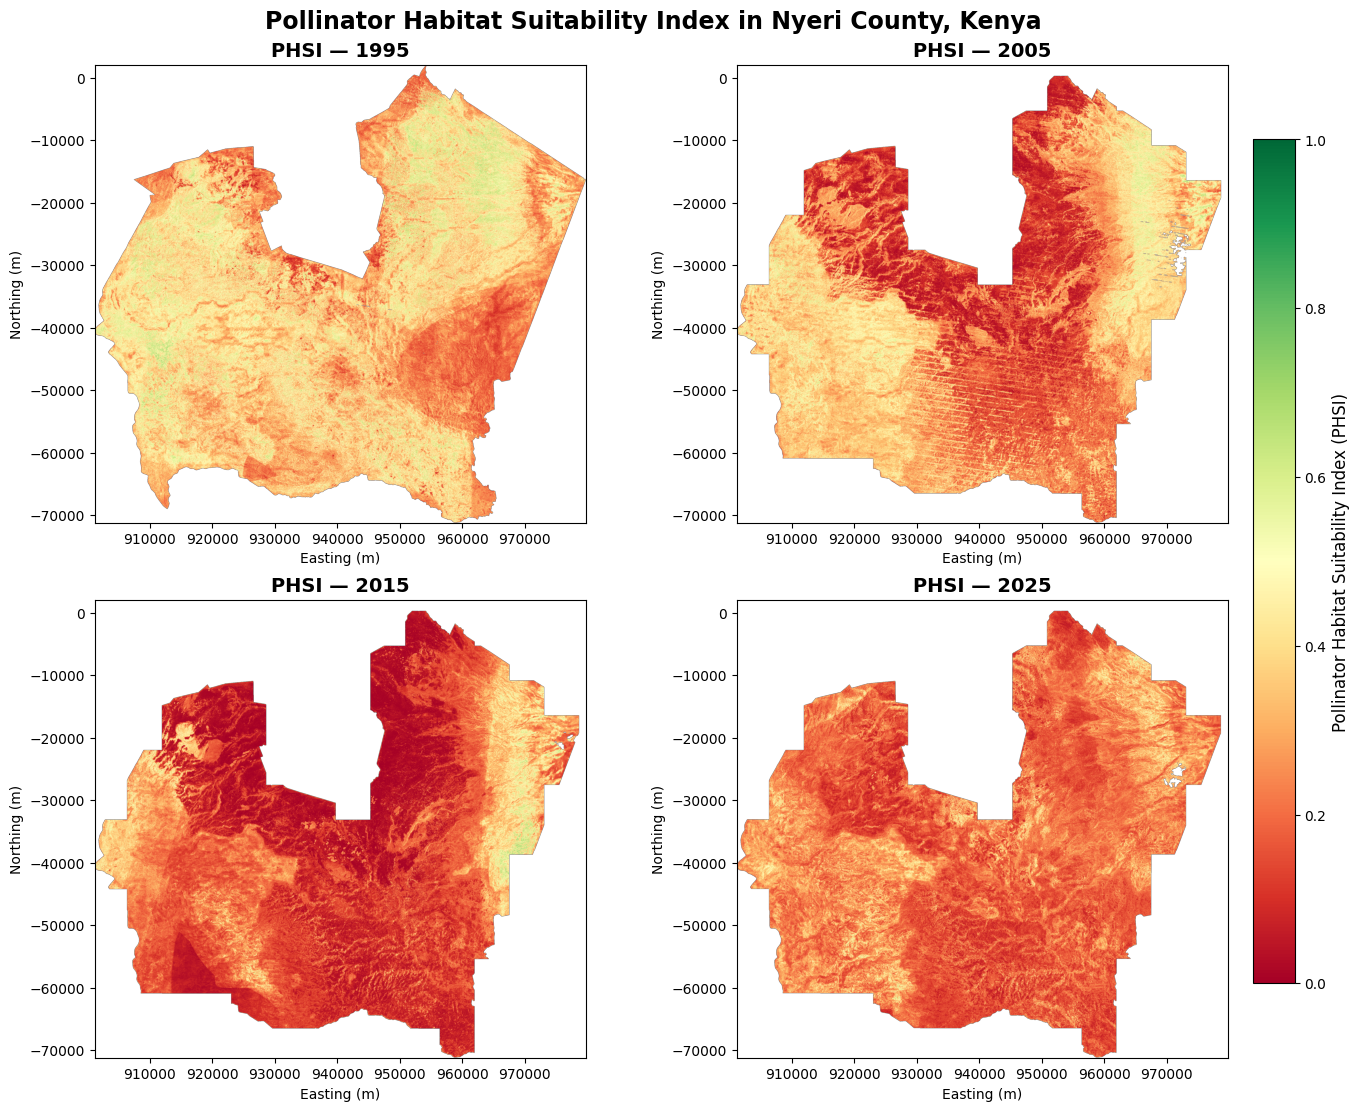

In [44]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# FOUR-YEAR CONTINUOUS PHSI MAP
# ------------------------------------------------------------

phsi_dir = Path("PHSI_outputs")
years = [1995, 2005, 2015, 2025]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 11),
    constrained_layout=True
)

images = []

for ax, year in zip(axes.flat, years):

    file_path = phsi_dir / f"PHSI_{year}.tif"

    with rasterio.open(file_path) as src:

        phsi = src.read(1, masked=True)
        bounds = src.bounds

        image = ax.imshow(
            phsi,
            extent=[
                bounds.left,
                bounds.right,
                bounds.bottom,
                bounds.top
            ],
            cmap="RdYlGn",
            vmin=0,
            vmax=1
        )

        images.append(image)

    ax.set_title(
        f"PHSI — {year}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

# ------------------------------------------------------------
# Common colour bar
# ------------------------------------------------------------

cbar = fig.colorbar(
    images[-1],
    ax=axes.ravel().tolist(),
    shrink=0.85,
    pad=0.02
)

cbar.set_label(
    "Pollinator Habitat Suitability Index (PHSI)",
    fontsize=12
)

fig.suptitle(
    "Pollinator Habitat Suitability Index in Nyeri County, Kenya",
    fontsize=17,
    fontweight="bold"
)

plt.show()

In [45]:
from pathlib import Path

# Current notebook folder
base_dir = Path.cwd()

print("Current folder:")
print(base_dir)
print("\nPossible boundary/vector files:")

vector_files = []
for ext in ["*.shp", "*.gpkg", "*.geojson", "*.json"]:
    vector_files.extend(base_dir.glob(ext))

if vector_files:
    for f in vector_files:
        print(f" - {f.name}")
else:
    print("No shapefile, GeoPackage, or GeoJSON found in this folder.")

Current folder:
D:\CODING\Modelling

Possible boundary/vector files:
No shapefile, GeoPackage, or GeoJSON found in this folder.


In [46]:
import geopandas as gpd
from pathlib import Path

base_dir = Path.cwd()

# Find shapefiles in the modelling folder
shapefiles = list(base_dir.glob("*.shp"))

print("Shapefiles found:")
for shp in shapefiles:
    print(" -", shp.name)

# Use the Nyeri shapefile
nyeri_shp = [f for f in shapefiles if "nyeri" in f.name.lower()][0]

# Read boundary
nyeri_boundary = gpd.read_file(nyeri_shp)

print("\nBoundary file:", nyeri_shp.name)
print("Number of features:", len(nyeri_boundary))
print("CRS:", nyeri_boundary.crs)
print("Geometry type:", nyeri_boundary.geometry.geom_type.unique())
print("Bounds:", nyeri_boundary.total_bounds)

print("\nColumns:")
print(list(nyeri_boundary.columns))

Shapefiles found:
 - Nyeri_county.shp

Boundary file: Nyeri_county.shp
Number of features: 1
CRS: EPSG:4326
Geometry type: <StringArray>
['Polygon']
Length: 1, dtype: str
Bounds: [ 3.66040382e+01 -6.44683676e-01  3.73078117e+01  1.54363020e-02]

Columns:
['adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'cod_versio', 'lang', 'lang1', 'lang2', 'lang3', 'adm1_ref_n', 'center_lat', 'center_lon', 'geometry']


In [47]:
import rasterio
import geopandas as gpd

# Read the first PHSI raster to get the exact mapping CRS
phsi_path = "PHSI_outputs/PHSI_1995.tif"

with rasterio.open(phsi_path) as src:
    phsi_crs = src.crs

print("PHSI raster CRS:", phsi_crs)
print("Original boundary CRS:", nyeri_boundary.crs)

# Reproject boundary to exactly match the PHSI raster CRS
nyeri_boundary_projected = nyeri_boundary.to_crs(phsi_crs)

print("\nReprojected boundary CRS:", nyeri_boundary_projected.crs)
print("Geometry type:", nyeri_boundary_projected.geometry.geom_type.unique())
print("Number of features:", len(nyeri_boundary_projected))
print("Projected bounds:", nyeri_boundary_projected.total_bounds)

PHSI raster CRS: EPSG:21096
Original boundary CRS: EPSG:4326

Reprojected boundary CRS: PROJCS["Arc 1960 / UTM zone 36N",GEOGCS["Arc 1960",DATUM["Arc_1960",SPHEROID["Clarke 1880 (RGS)",6378249.145,293.465,AUTHORITY["EPSG","7012"]],AUTHORITY["EPSG","6210"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4210"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",33],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","21096"]]
Geometry type: <StringArray>
['Polygon']
Length: 1, dtype: str
Number of features: 1
Projected bounds: [901212.47284405 -71142.99426325 979720.02355979   2010.1747683 ]


In [48]:
from pathlib import Path

# Create output folder for RF diagnostics
rf_output_dir = Path("RF_outputs")
rf_output_dir.mkdir(exist_ok=True)

print("RF output folder:", rf_output_dir.resolve())

# Check the key objects currently available
objects_to_check = [
    "final_preprocessor",
    "final_rf",
    "final_model",
    "X_train",
    "X_test",
    "y_train",
    "y_test"
]

for obj in objects_to_check:
    print(f"{obj}: {'AVAILABLE' if obj in globals() else 'NOT FOUND'}")

RF output folder: D:\CODING\Modelling\RF_outputs
final_preprocessor: AVAILABLE
final_rf: AVAILABLE
final_model: NOT FOUND
X_train: NOT FOUND
X_test: NOT FOUND
y_train: AVAILABLE
y_test: NOT FOUND


In [49]:
print("FINAL RF MODEL")
print(final_rf)

print("\nFINAL PREPROCESSOR")
print(final_preprocessor)

print("\nRF model fitted:", hasattr(final_rf, "feature_importances_"))
print("Preprocessor fitted:",
      hasattr(final_preprocessor, "transformers_"))


FINAL RF MODEL
RandomForestClassifier(class_weight='balanced', max_depth=15,
                       min_samples_leaf=5, n_estimators=500, n_jobs=-1,
                       random_state=42)

FINAL PREPROCESSOR
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['SOC', 'Aspect', 'Slope', 'PH', 'TRI', 'TWI',
                                  'NDVI', 'PCI', 'LST', 'pop', 'rain']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['LULC'])])

RF model fitted: True
Preprocessor fitted: True


RF FEATURE IMPORTANCE


,Predictor,Importance
4,PCI,0.1348
1,LST,0.1188
3,NDVI,0.0909
10,pop,0.0801
8,TRI,0.0792
11,rain,0.0775
6,SOC,0.0770
0,Aspect,0.0765
9,TWI,0.0756
5,PH,0.0735


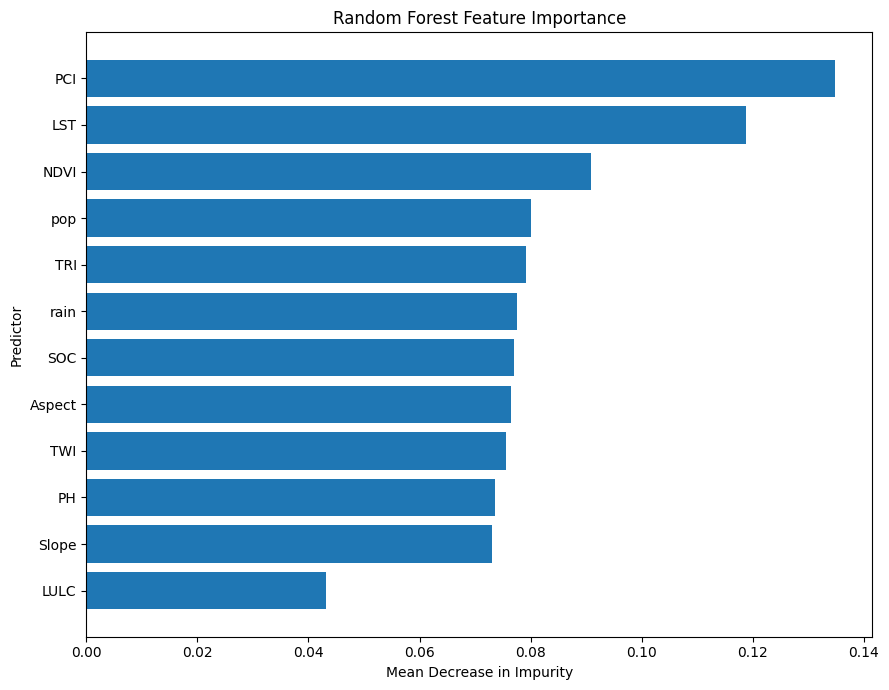


Figure saved to:
D:\CODING\Modelling\RF_outputs\RF_feature_importance.png


In [50]:
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Get processed feature names from the fitted preprocessor
# ------------------------------------------------------------
feature_names = final_preprocessor.get_feature_names_out()

# Get RF impurity-based feature importance
importances = final_rf.feature_importances_

# Create initial importance table
importance_df = pd.DataFrame({
    "Processed_Feature": feature_names,
    "Importance": importances
})

# ------------------------------------------------------------
# 2. Convert processed names back to original predictors
# ------------------------------------------------------------
def get_original_predictor(feature_name):
    if feature_name.startswith("num__"):
        return feature_name.replace("num__", "")
    elif feature_name.startswith("cat__LULC_"):
        return "LULC"
    else:
        return feature_name

importance_df["Predictor"] = importance_df["Processed_Feature"].apply(
    get_original_predictor
)

# ------------------------------------------------------------
# 3. Aggregate the one-hot LULC variables
# ------------------------------------------------------------
aggregated_importance = (
    importance_df
    .groupby("Predictor", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

# ------------------------------------------------------------
# 4. Display ranked importance table
# ------------------------------------------------------------
print("RF FEATURE IMPORTANCE")
print("=" * 50)

display(
    aggregated_importance.style
    .format({"Importance": "{:.4f}"})
)

# ------------------------------------------------------------
# 5. Create visualization
# ------------------------------------------------------------
plot_df = aggregated_importance.sort_values("Importance", ascending=True)

plt.figure(figsize=(9, 7))

plt.barh(
    plot_df["Predictor"],
    plot_df["Importance"]
)

plt.xlabel("Mean Decrease in Impurity")
plt.ylabel("Predictor")
plt.title("Random Forest Feature Importance")
plt.tight_layout()

# Save figure
output_file = rf_output_dir / "RF_feature_importance.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")

plt.show()

print("\nFigure saved to:")
print(output_file.resolve())

In [51]:
from sklearn.model_selection import GroupShuffleSplit

# ------------------------------------------------------------
# Load modelling data
# ------------------------------------------------------------
data = pd.read_csv("modelling_data.csv")

# Same predictor set used by the final RF
reduced_predictors = [
    "SOC", "Aspect", "Slope", "PH", "TRI", "TWI",
    "NDVI", "PCI", "LST", "pop", "rain", "LULC"
]

# Target
X = data[reduced_predictors].copy()
y = data["Presence"].copy()

# Spatial grouping variable
groups = data["OBJECTID"]

# ------------------------------------------------------------
# Recreate the same spatial holdout
# ------------------------------------------------------------
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_holdout = X.iloc[test_idx].copy()
y_holdout = y.iloc[test_idx].copy()

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------
print("Holdout rows:", len(X_holdout))
print("Holdout unique locations:", X_holdout.index.size)
print("Holdout presence:", int(y_holdout.sum()))
print("Holdout background:", int((y_holdout == 0).sum()))

print("\nHoldout prevalence:",
      round(y_holdout.mean(), 4))

Holdout rows: 5000
Holdout unique locations: 5000
Holdout presence: 243
Holdout background: 4757

Holdout prevalence: 0.0486


In [52]:
# Verify actual number of unique spatial locations
train_objectids = set(data.iloc[train_idx]["OBJECTID"])
holdout_objectids = set(data.iloc[test_idx]["OBJECTID"])

print("Holdout rows:", len(test_idx))
print("Holdout unique OBJECTIDs:", len(holdout_objectids))
print("Training unique OBJECTIDs:", len(train_objectids))
print("Spatial overlap:", len(train_objectids.intersection(holdout_objectids)))

print("\nExpected:")
print("Holdout locations: 1250")
print("Training locations: 3750")
print("Spatial overlap: 0")

Holdout rows: 5000
Holdout unique OBJECTIDs: 1250
Training unique OBJECTIDs: 3750
Spatial overlap: 0

Expected:
Holdout locations: 1250
Training locations: 3750
Spatial overlap: 0


In [54]:
from sklearn.inspection import permutation_importance
import numpy as np

# ------------------------------------------------------------
# 1. Transform the holdout data using the SAME fitted
#    preprocessing used by the final RF
# ------------------------------------------------------------
X_holdout_processed = final_preprocessor.transform(X_holdout)

# ------------------------------------------------------------
# 2. Calculate permutation importance
# ------------------------------------------------------------
perm_result = permutation_importance(
    final_rf,
    X_holdout_processed,
    y_holdout,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 3. Recover processed feature names
# ------------------------------------------------------------
processed_features = final_preprocessor.get_feature_names_out()

perm_df = pd.DataFrame({
    "Processed_Feature": processed_features,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_SD": perm_result.importances_std
})

# ------------------------------------------------------------
# 4. Convert one-hot LULC components back to LULC
# ------------------------------------------------------------
perm_df["Predictor"] = perm_df["Processed_Feature"].apply(
    get_original_predictor
)

# ------------------------------------------------------------
# 5. Aggregate LULC components
# ------------------------------------------------------------
perm_aggregated = (
    perm_df
    .groupby("Predictor", as_index=False)
    .agg(
        Importance_Mean=("Importance_Mean", "sum"),
        Importance_SD=("Importance_SD", "sum")
    )
    .sort_values("Importance_Mean", ascending=False)
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------
print("PERMUTATION IMPORTANCE — INDEPENDENT SPATIAL HOLDOUT")
print("=" * 65)

display(
    perm_aggregated.style.format({
        "Importance_Mean": "{:.5f}",
        "Importance_SD": "{:.5f}"
    })
)

PERMUTATION IMPORTANCE — INDEPENDENT SPATIAL HOLDOUT


,Predictor,Importance_Mean,Importance_SD
4,PCI,0.02433,0.00608
2,LULC,0.01249,0.00871
9,TWI,0.00646,0.00108
8,TRI,0.00601,0.00265
1,LST,0.00574,0.00717
10,pop,0.00514,0.00381
6,SOC,0.00496,0.00435
11,rain,0.00226,0.00480
7,Slope,0.00008,0.00236
0,Aspect,-0.00003,0.00411


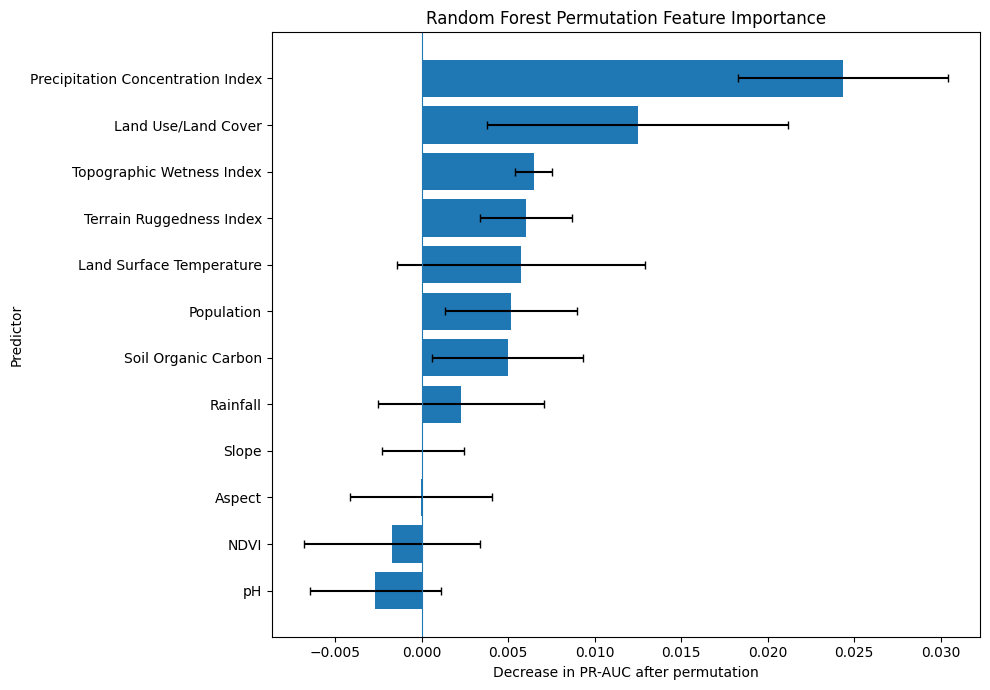

Figure saved to:
D:\CODING\Modelling\RF_outputs\RF_permutation_importance.png


In [55]:
# ------------------------------------------------------------
# PERMUTATION IMPORTANCE FIGURE
# ------------------------------------------------------------

# Sort for horizontal bar chart
plot_perm = perm_aggregated.sort_values(
    "Importance_Mean",
    ascending=True
).copy()

# Cleaner labels
plot_perm["Predictor"] = plot_perm["Predictor"].replace({
    "pop": "Population",
    "rain": "Rainfall",
    "PH": "pH",
    "SOC": "Soil Organic Carbon",
    "PCI": "Precipitation Concentration Index",
    "LST": "Land Surface Temperature",
    "NDVI": "NDVI",
    "TWI": "Topographic Wetness Index",
    "TRI": "Terrain Ruggedness Index",
    "LULC": "Land Use/Land Cover",
    "Slope": "Slope",
    "Aspect": "Aspect"
})

plt.figure(figsize=(10, 7))

plt.barh(
    plot_perm["Predictor"],
    plot_perm["Importance_Mean"],
    xerr=plot_perm["Importance_SD"],
    capsize=3
)

plt.axvline(
    x=0,
    linewidth=0.8
)

plt.xlabel("Decrease in PR-AUC after permutation")
plt.ylabel("Predictor")
plt.title("Random Forest Permutation Feature Importance")
plt.tight_layout()

# Save figure
perm_output = rf_output_dir / "RF_permutation_importance.png"

plt.savefig(
    perm_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:")
print(perm_output.resolve())

ROC-AUC: 0.6871


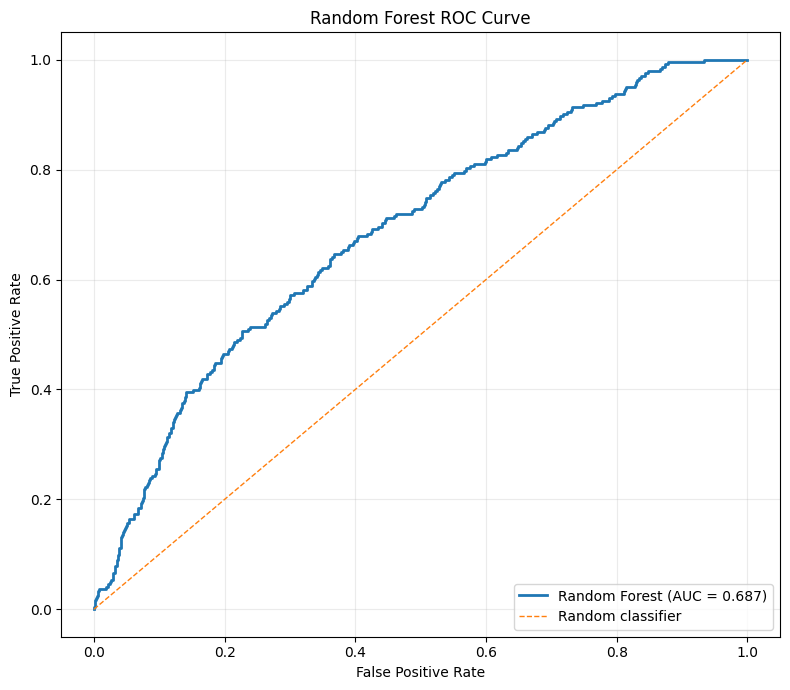


Figure saved to:
D:\CODING\Modelling\RF_outputs\RF_ROC_curve.png


In [56]:
from sklearn.metrics import roc_curve, roc_auc_score

# ------------------------------------------------------------
# 1. Generate RF probability predictions for the holdout
# ------------------------------------------------------------
X_holdout_processed = final_preprocessor.transform(X_holdout)

y_prob = final_rf.predict_proba(
    X_holdout_processed
)[:, 1]

# ------------------------------------------------------------
# 2. Calculate ROC curve and AUC
# ------------------------------------------------------------
fpr, tpr, thresholds = roc_curve(
    y_holdout,
    y_prob
)

roc_auc = roc_auc_score(
    y_holdout,
    y_prob
)

print(f"ROC-AUC: {roc_auc:.4f}")

# ------------------------------------------------------------
# 3. Plot ROC curve
# ------------------------------------------------------------
plt.figure(figsize=(8, 7))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1,
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)

plt.tight_layout()

# ------------------------------------------------------------
# 4. Save figure
# ------------------------------------------------------------
roc_output = rf_output_dir / "RF_ROC_curve.png"

plt.savefig(
    roc_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved to:")
print(roc_output.resolve())

PR-AUC: 0.0998
Baseline prevalence: 0.0486


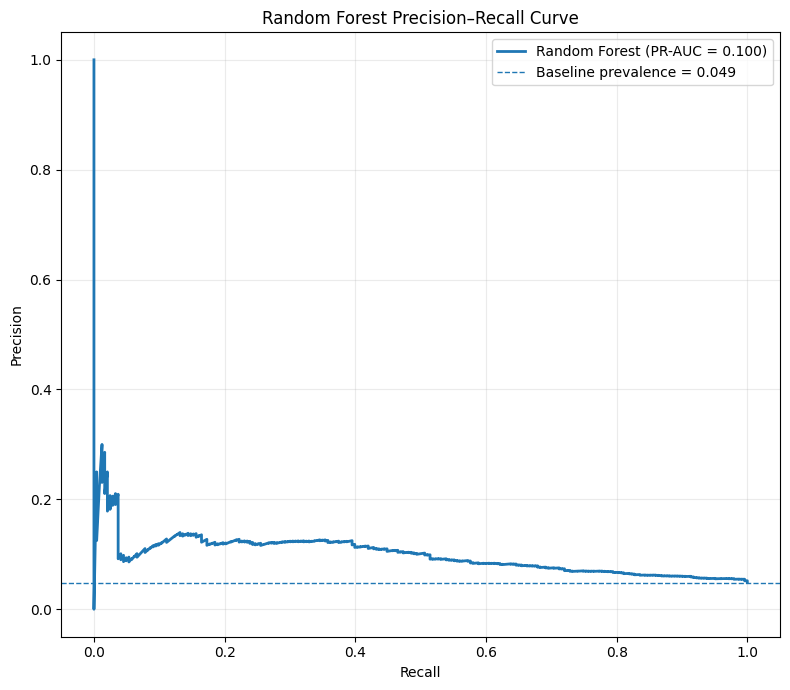


Figure saved to:
D:\CODING\Modelling\RF_outputs\RF_precision_recall_curve.png


In [57]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# ------------------------------------------------------------
# 1. Calculate Precision–Recall curve
# ------------------------------------------------------------
precision, recall, pr_thresholds = precision_recall_curve(
    y_holdout,
    y_prob
)

pr_auc = average_precision_score(
    y_holdout,
    y_prob
)

# Baseline prevalence
baseline_prevalence = y_holdout.mean()

print(f"PR-AUC: {pr_auc:.4f}")
print(f"Baseline prevalence: {baseline_prevalence:.4f}")

# ------------------------------------------------------------
# 2. Plot Precision–Recall curve
# ------------------------------------------------------------
plt.figure(figsize=(8, 7))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"Random Forest (PR-AUC = {pr_auc:.3f})"
)

plt.axhline(
    baseline_prevalence,
    linestyle="--",
    linewidth=1,
    label=f"Baseline prevalence = {baseline_prevalence:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest Precision–Recall Curve")
plt.legend(loc="upper right")
plt.grid(alpha=0.25)

plt.tight_layout()

# ------------------------------------------------------------
# 3. Save figure
# ------------------------------------------------------------
pr_output = rf_output_dir / "RF_precision_recall_curve.png"

plt.savefig(
    pr_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved to:")
print(pr_output.resolve())

CONFUSION MATRIX — THRESHOLD = 0.50

Confusion matrix:
[[4462  295]
 [ 201   42]]

True Negatives : 4462
False Positives: 295
False Negatives: 201
True Positives : 42

Classification metrics:
Accuracy          : 0.9008
Precision         : 0.1246
Sensitivity/Recall: 0.1728
Specificity       : 0.9380
F1-score          : 0.1448
Balanced Accuracy : 0.5554


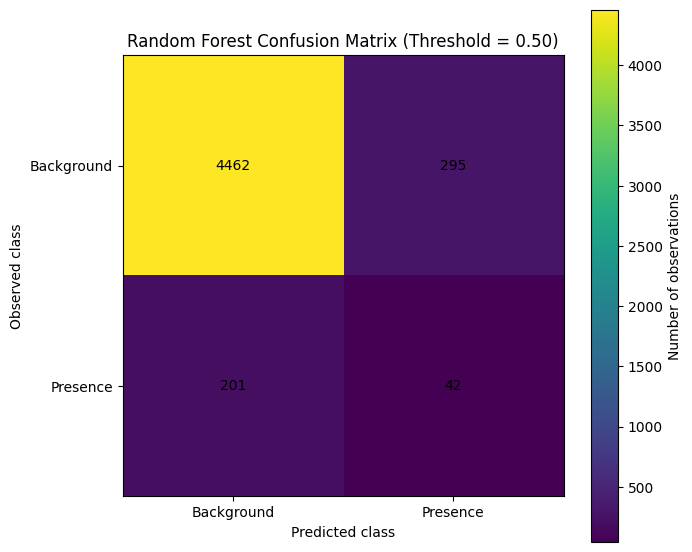


Figure saved to:
D:\CODING\Modelling\RF_outputs\RF_confusion_matrix.png


In [58]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 1. Reference classification threshold
# ------------------------------------------------------------
threshold = 0.50

y_pred = (y_prob >= threshold).astype(int)

# ------------------------------------------------------------
# 2. Confusion matrix
# ------------------------------------------------------------
cm = confusion_matrix(
    y_holdout,
    y_pred
)

tn, fp, fn, tp = cm.ravel()

# ------------------------------------------------------------
# 3. Classification metrics
# ------------------------------------------------------------
accuracy = accuracy_score(y_holdout, y_pred)
precision_value = precision_score(y_holdout, y_pred, zero_division=0)
sensitivity = recall_score(y_holdout, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
f1 = f1_score(y_holdout, y_pred, zero_division=0)
balanced_acc = balanced_accuracy_score(y_holdout, y_pred)

print("CONFUSION MATRIX — THRESHOLD = 0.50")
print("=" * 50)

print("\nConfusion matrix:")
print(cm)

print("\nTrue Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

print("\nClassification metrics:")
print(f"Accuracy          : {accuracy:.4f}")
print(f"Precision         : {precision_value:.4f}")
print(f"Sensitivity/Recall: {sensitivity:.4f}")
print(f"Specificity       : {specificity:.4f}")
print(f"F1-score          : {f1:.4f}")
print(f"Balanced Accuracy : {balanced_acc:.4f}")

# ------------------------------------------------------------
# 4. Plot confusion matrix
# ------------------------------------------------------------
plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.xticks(
    [0, 1],
    ["Background", "Presence"]
)

plt.yticks(
    [0, 1],
    ["Background", "Presence"]
)

plt.xlabel("Predicted class")
plt.ylabel("Observed class")
plt.title("Random Forest Confusion Matrix (Threshold = 0.50)")

# Add values inside cells
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar(label="Number of observations")
plt.tight_layout()

# ------------------------------------------------------------
# 5. Save figure
# ------------------------------------------------------------
cm_output = rf_output_dir / "RF_confusion_matrix.png"

plt.savefig(
    cm_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved to:")
print(cm_output.resolve())

In [59]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
import numpy as np

# ------------------------------------------------------------
# Continuous RF probability-score diagnostics
# ------------------------------------------------------------

rmse = np.sqrt(
    mean_squared_error(
        y_holdout,
        y_prob
    )
)

mae = mean_absolute_error(
    y_holdout,
    y_prob
)

r2 = r2_score(
    y_holdout,
    y_prob
)

print("RF CONTINUOUS SCORE DIAGNOSTICS")
print("=" * 50)

print(f"RMSE: {rmse:.4f}")
print(f"MAE : {mae:.4f}")
print(f"R²  : {r2:.4f}")

print("\nInterpretation:")
print("These metrics describe the error of RF probability scores")
print("relative to the binary presence/background observations.")
print("They are NOT treated as the primary RF classification metrics.")

RF CONTINUOUS SCORE DIAGNOSTICS
RMSE: 0.3160
MAE : 0.2644
R²  : -1.1592

Interpretation:
These metrics describe the error of RF probability scores
relative to the binary presence/background observations.
They are NOT treated as the primary RF classification metrics.


RF RESIDUAL DIAGNOSTICS
Mean residual   : -0.2011
Median residual : -0.2124
Std. deviation  : 0.2437
Minimum residual: -0.7879
Maximum residual: 0.9640


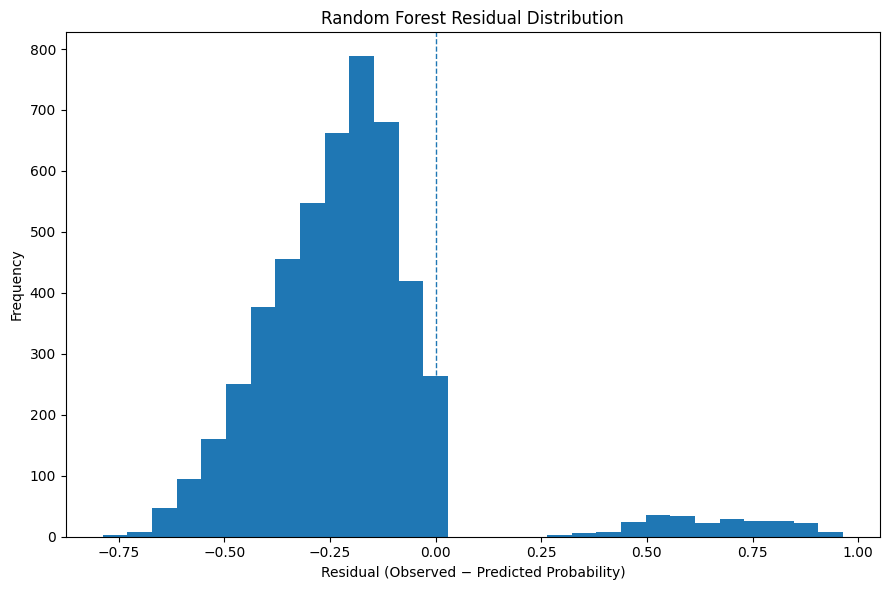


Residual distribution saved to:
D:\CODING\Modelling\RF_outputs\RF_residual_distribution.png


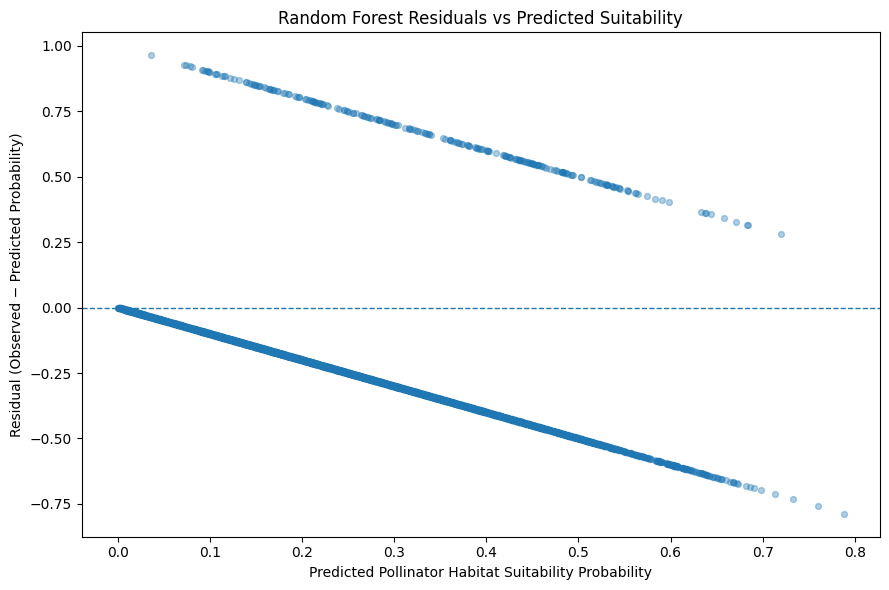


Residual scatter plot saved to:
D:\CODING\Modelling\RF_outputs\RF_residuals_vs_prediction.png


In [60]:
# ------------------------------------------------------------
# RF RESIDUAL ANALYSIS
# ------------------------------------------------------------

# Calculate residuals
residuals = y_holdout.to_numpy() - y_prob

# Create residual dataframe
residual_df = pd.DataFrame({
    "Observed": y_holdout.to_numpy(),
    "Predicted_Probability": y_prob,
    "Residual": residuals
})

# ------------------------------------------------------------
# Residual statistics
# ------------------------------------------------------------
print("RF RESIDUAL DIAGNOSTICS")
print("=" * 50)

print(f"Mean residual   : {residuals.mean():.4f}")
print(f"Median residual : {np.median(residuals):.4f}")
print(f"Std. deviation  : {residuals.std():.4f}")
print(f"Minimum residual: {residuals.min():.4f}")
print(f"Maximum residual: {residuals.max():.4f}")

# ------------------------------------------------------------
# Plot 1: Residual distribution
# ------------------------------------------------------------
plt.figure(figsize=(9, 6))

plt.hist(
    residuals,
    bins=30
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Residual (Observed − Predicted Probability)")
plt.ylabel("Frequency")
plt.title("Random Forest Residual Distribution")

plt.tight_layout()

residual_hist_output = rf_output_dir / "RF_residual_distribution.png"

plt.savefig(
    residual_hist_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nResidual distribution saved to:")
print(residual_hist_output.resolve())

# ------------------------------------------------------------
# Plot 2: Residuals versus predicted probability
# ------------------------------------------------------------
plt.figure(figsize=(9, 6))

plt.scatter(
    y_prob,
    residuals,
    alpha=0.35,
    s=18
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Predicted Pollinator Habitat Suitability Probability")
plt.ylabel("Residual (Observed − Predicted Probability)")
plt.title("Random Forest Residuals vs Predicted Suitability")

plt.tight_layout()

residual_scatter_output = rf_output_dir / "RF_residuals_vs_prediction.png"

plt.savefig(
    residual_scatter_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nResidual scatter plot saved to:")
print(residual_scatter_output.resolve())

In [61]:
# ------------------------------------------------------------
# SPATIAL RESIDUAL DATA
# ------------------------------------------------------------

# Extract holdout coordinates
spatial_residuals = data.iloc[test_idx][
    ["OBJECTID", "Longitude", "Latitude"]
].copy()

# Add observed, predicted probability and residual
spatial_residuals["Observed"] = y_holdout.to_numpy()
spatial_residuals["Predicted_Probability"] = y_prob
spatial_residuals["Residual"] = residuals

# Absolute error is useful for identifying areas with larger errors
spatial_residuals["Absolute_Error"] = np.abs(
    spatial_residuals["Residual"]
)

print("SPATIAL RESIDUAL DATA")
print("=" * 50)

print("Number of observations:", len(spatial_residuals))
print("Unique locations:", spatial_residuals["OBJECTID"].nunique())

print("\nResidual summary:")
display(
    spatial_residuals[
        ["Predicted_Probability", "Residual", "Absolute_Error"]
    ].describe().round(4)
)

print("\nFirst five observations:")
display(spatial_residuals.head())

SPATIAL RESIDUAL DATA
Number of observations: 5000
Unique locations: 1250

Residual summary:


,Predicted_Probability,Residual,Absolute_Error
count,5000.0000,5000.0000,5000.0000
mean,0.2497,-0.2011,0.2644
std,0.1508,0.2438,0.1729
min,0.0000,-0.7879,0.0000
25%,0.1354,-0.3387,0.1373
50%,0.2279,-0.2124,0.2339
75%,0.3546,-0.1169,0.3685
max,0.7879,0.9640,0.9640



First five observations:


,OBJECTID,Longitude,Latitude,Observed,Predicted_Probability,Residual,Absolute_Error
8,9,37.151405,-0.243092,1,0.432313,0.567687,0.567687
12,13,36.811470,-0.378237,1,0.529648,0.470352,0.470352
14,15,36.763755,-0.163790,0,0.525298,-0.525298,0.525298
17,18,36.822571,-0.144868,0,0.136596,-0.136596,0.136596
19,20,37.054060,-0.308484,0,0.542036,-0.542036,0.542036


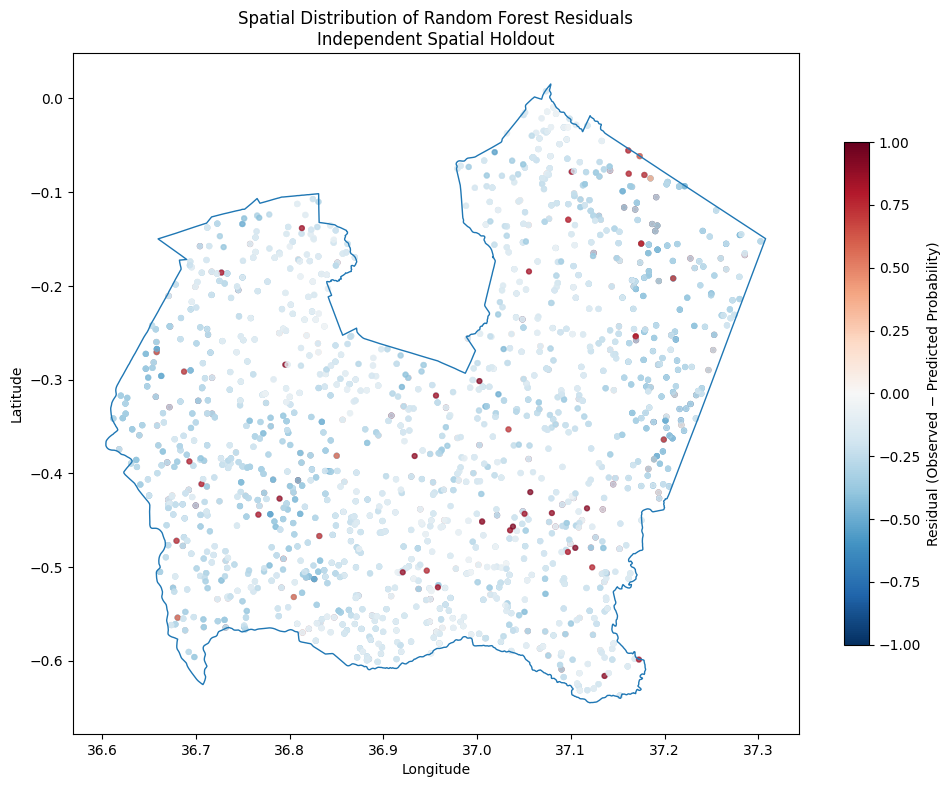

Spatial residual map saved to:
D:\CODING\Modelling\RF_outputs\RF_spatial_residuals.png


In [62]:
import geopandas as gpd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load Nyeri County boundary
# ------------------------------------------------------------
boundary_path = r"D:\CODING\Modelling\Nyeri_county.shp"

nyeri_boundary = gpd.read_file(boundary_path)

# Make sure boundary is in WGS84 to match Longitude/Latitude
if nyeri_boundary.crs is not None:
    nyeri_boundary = nyeri_boundary.to_crs("EPSG:4326")

# ------------------------------------------------------------
# Convert residual data to GeoDataFrame
# ------------------------------------------------------------
spatial_gdf = gpd.GeoDataFrame(
    spatial_residuals.copy(),
    geometry=gpd.points_from_xy(
        spatial_residuals["Longitude"],
        spatial_residuals["Latitude"]
    ),
    crs="EPSG:4326"
)

# ------------------------------------------------------------
# Plot spatial residuals
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))

nyeri_boundary.boundary.plot(
    ax=ax,
    linewidth=1
)

spatial_gdf.plot(
    ax=ax,
    column="Residual",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    markersize=12,
    alpha=0.75,
    legend=True,
    legend_kwds={
        "label": "Residual (Observed − Predicted Probability)",
        "shrink": 0.7
    }
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    "Spatial Distribution of Random Forest Residuals\n"
    "Independent Spatial Holdout"
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------
spatial_residual_output = (
    rf_output_dir / "RF_spatial_residuals.png"
)

plt.savefig(
    spatial_residual_output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Spatial residual map saved to:")
print(spatial_residual_output.resolve())


In [63]:
# ------------------------------------------------------------
# RF PERFORMANCE SUMMARY
# ------------------------------------------------------------

rf_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "RMSE",
        "MAE",
        "R²",
        "Spatial CV ROC-AUC (Mean)",
        "Spatial CV ROC-AUC (SD)",
        "Spatial CV PR-AUC (Mean)",
        "Spatial CV PR-AUC (SD)"
    ],
    "Value": [
        roc_auc,
        pr_auc,
        rmse,
        mae,
        r2,
        0.6472,
        0.0287,
        0.0761,
        0.0088
    ]
})

print("RANDOM FOREST MODEL PERFORMANCE SUMMARY")
print("=" * 60)

display(
    rf_summary.style.format({
        "Value": "{:.4f}"
    })
)

# ------------------------------------------------------------
# Save summary as CSV
# ------------------------------------------------------------
rf_summary_output = rf_output_dir / "RF_performance_summary.csv"

rf_summary.to_csv(
    rf_summary_output,
    index=False
)

print("\nPerformance summary saved to:")
print(rf_summary_output.resolve())

RANDOM FOREST MODEL PERFORMANCE SUMMARY


,Metric,Value
0,ROC-AUC,0.6871
1,PR-AUC,0.0998
2,RMSE,0.3160
3,MAE,0.2644
4,R²,-1.1592
5,Spatial CV ROC-AUC (Mean),0.6472
6,Spatial CV ROC-AUC (SD),0.0287
7,Spatial CV PR-AUC (Mean),0.0761
8,Spatial CV PR-AUC (SD),0.0088



Performance summary saved to:
D:\CODING\Modelling\RF_outputs\RF_performance_summary.csv
